In [1]:
# Step 1: download slurm-log.csv in Range chunks (< 8 MiB) and verify its size
from pathlib import Path
import urllib.request
import time

PROJECT_DIR = Path.cwd().parent          # notebooks live in notebooks/
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

BUCKET = "mit-supercloud-dataset"
PREFIX = "datacenter-challenge/202201"
FILENAME = "slurm-log.csv"
URL = f"https://{BUCKET}.s3.amazonaws.com/{PREFIX}/{FILENAME}"
EXPECTED_SIZE = 103_165_427
CHUNK = 4 * 1024 * 1024                  # 4 MiB, safely below the 8 MiB VPN limit
HEADERS = {"User-Agent": "Mozilla/5.0"}

dest = RAW_DIR / FILENAME

# 1) Ask the server for the file size
req = urllib.request.Request(URL, method="HEAD", headers=HEADERS)
with urllib.request.urlopen(req, timeout=60) as r:
    remote_size = int(r.headers["Content-Length"])
print(f"Remote size : {remote_size:,} bytes")
print(f"Expected    : {EXPECTED_SIZE:,} bytes -> match: {remote_size == EXPECTED_SIZE}")

# 2) Resume-aware chunked download
start = dest.stat().st_size if dest.exists() else 0
if start > remote_size:                  # corrupted partial file: start over
    dest.unlink()
    start = 0
print(f"Resuming from byte {start:,}")

t0 = time.time()
with open(dest, "ab") as f:
    pos = start
    while pos < remote_size:
        end = min(pos + CHUNK, remote_size) - 1
        req = urllib.request.Request(URL, headers={**HEADERS, "Range": f"bytes={pos}-{end}"})
        with urllib.request.urlopen(req, timeout=120) as r:
            data = r.read()
        expected_len = end - pos + 1
        if len(data) != expected_len:
            raise RuntimeError(f"Chunk at {pos} returned {len(data)} bytes, expected {expected_len}")
        f.write(data)
        pos = end + 1
        if (pos // CHUNK) % 5 == 0 or pos >= remote_size:
            print(f"  {pos / remote_size * 100:5.1f}%  ({pos:,} bytes)")

# 3) Verify
final_size = dest.stat().st_size
print(f"\nDone in {time.time() - t0:.0f} s")
print(f"Local size  : {final_size:,} bytes")
print("SIZE OK" if final_size == EXPECTED_SIZE else "SIZE MISMATCH - do not continue")

Remote size : 103,165,427 bytes
Expected    : 103,165,427 bytes -> match: True
Resuming from byte 0
   20.3%  (20,971,520 bytes)
   40.7%  (41,943,040 bytes)
   61.0%  (62,914,560 bytes)
   81.3%  (83,886,080 bytes)
  100.0%  (103,165,427 bytes)

Done in 94 s
Local size  : 103,165,427 bytes
SIZE OK


In [2]:
# Step 2: inspect the structure of slurm-log.csv (columns, dtypes, first rows, row count)
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"

# Peek at the raw text first, to see the header and delimiter exactly as stored
with open(SLURM_PATH, "r", encoding="utf-8", errors="replace") as f:
    for i in range(3):
        print(f"RAW line {i}: {f.readline().rstrip()[:300]}")

# Lazy scan, then collect only what we need
lf = pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
schema = lf.collect_schema()

print("\nColumns and dtypes:")
for name, dtype in schema.items():
    print(f"  {name:25s} {dtype}")

n_rows = lf.select(pl.len()).collect().item()
print(f"\nTotal rows: {n_rows:,}")

print("\nFirst 5 rows:")
print(lf.head(5).collect())

RAW line 0: id_job,id_array_job,id_array_task,id_user,kill_requid,nodes_alloc,nodelist,cpus_req,derived_ec,exit_code,gres_used,array_max_tasks,array_task_pending,constraints,flags,mem_req,partition,priority,state,timelimit,time_submit,time_eligible,time_start,time_end,time_suspended,track_steps,tres_alloc,tres_
RAW line 1: 82691694838059,38873353215144,2504,42770088536256,61026541062099,1,['r9189566-n911952'],20,0,0,,0,0,xeon-g6,4,9223372036854784308,normal,10237,3,4294967295,1609535703,1609535704,1609806297,1609806605,0,0,"1=20,2=170000,4=1,5=20","1=20,2=170000,4=1,5=20",OTHER
RAW line 2: 3434806870797,38873353215144,2523,42770088536256,61026541062099,1,['r9189566-n911952'],20,0,0,,0,0,xeon-g6,4,9223372036854784308,normal,10237,3,4294967295,1609535703,1609535704,1609806607,1609807004,0,0,"1=20,2=170000,4=1,5=20","1=20,2=170000,4=1,5=20",OTHER

Columns and dtypes:
  id_job                    Int64
  id_array_job              Int64
  id_array_task             Int64
  id_user            

In [3]:
# Step 3: time range and key categorical columns of slurm-log.csv
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"

lf = pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)

# 1) Time range, assuming Unix seconds (to be verified by the dates below)
rng = lf.select(
    pl.col("time_submit").min().alias("submit_min"),
    pl.col("time_submit").max().alias("submit_max"),
    pl.col("time_start").min().alias("start_min"),
    pl.col("time_start").max().alias("start_max"),
    pl.col("time_end").min().alias("end_min"),
    pl.col("time_end").max().alias("end_max"),
).collect()
print("Raw time range (epoch values):")
print(rng)

print("\nAs dates (assuming Unix seconds, UTC):")
for c in rng.columns:
    v = rng[c][0]
    print(f"  {c:11s} {v:>12,}  ->  {pl.from_epoch(pl.Series([v]), time_unit='s')[0]}")

# 2) Categorical columns
for col in ["partition", "job_type", "gres_used", "constraints"]:
    print(f"\nTop values of {col}:")
    print(
        lf.group_by(col).agg(pl.len().alias("n_jobs"))
          .sort("n_jobs", descending=True).head(12).collect()
    )

# 3) Sanity: rows with start/end <= 0 or end < start
bad = lf.select(
    (pl.col("time_start") <= 0).sum().alias("start_le_0"),
    (pl.col("time_end") <= 0).sum().alias("end_le_0"),
    (pl.col("time_end") < pl.col("time_start")).sum().alias("end_before_start"),
).collect()
print("\nSanity checks:")
print(bad)

Raw time range (epoch values):
shape: (1, 6)
┌────────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ submit_min ┆ submit_max ┆ start_min  ┆ start_max  ┆ end_min    ┆ end_max    │
│ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        │
│ i64        ┆ i64        ┆ i64        ┆ i64        ┆ i64        ┆ i64        │
╞════════════╪════════════╪════════════╪════════════╪════════════╪════════════╡
│ 1609535703 ┆ 1633100281 ┆ 1609806297 ┆ 1633100615 ┆ 1609806605 ┆ 1633101131 │
└────────────┴────────────┴────────────┴────────────┴────────────┴────────────┘

As dates (assuming Unix seconds, UTC):
  submit_min  1,609,535,703  ->  2021-01-01 21:15:03
  submit_max  1,633,100,281  ->  2021-10-01 14:58:01
  start_min   1,609,806,297  ->  2021-01-05 00:24:57
  start_max   1,633,100,615  ->  2021-10-01 15:03:35
  end_min     1,609,806,605  ->  2021-01-05 00:30:05
  end_max     1,633,101,131  ->  2021-10-01 15:12:11

Top values of partition:
shape: (5, 

In [4]:
# Step 4: download small reference files and print tres-mapping.txt
from pathlib import Path
import urllib.request

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201"
HEADERS = {"User-Agent": "Mozilla/5.0"}
FILES = ["tres-mapping.txt", "README.md", "labelled_jobids.csv", "labelled_job_stats.csv"]

for name in FILES:
    url = f"{BASE}/{name}"
    dest = RAW_DIR / name
    req = urllib.request.Request(url, headers=HEADERS)
    with urllib.request.urlopen(req, timeout=60) as r:
        data = r.read()
    dest.write_bytes(data)
    print(f"{name:25s} {len(data):>10,} bytes saved")

print("\n===== tres-mapping.txt =====")
print((RAW_DIR / "tres-mapping.txt").read_text(errors="replace"))

tres-mapping.txt                 111 bytes saved
README.md                      7,616 bytes saved
labelled_jobids.csv           82,332 bytes saved
labelled_job_stats.csv           339 bytes saved

===== tres-mapping.txt =====
tres_id,resource_type
1,cpu
2,mem
3,energy
4,node
5,billing
6,fs
7,vmem
8,pages
1001,gpu:tesla
1002,gpu:volta 



In [5]:
# Step 5: identify GPU jobs via tres_alloc (codes 1001 = gpu:tesla, 1002 = gpu:volta)
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"

lf = pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)

# Extract the GPU count from tres_alloc (e.g. "1=20,2=170000,4=1,5=20,1002=2")
gpu_lf = lf.with_columns(
    pl.col("tres_alloc").str.extract(r"(?:^|,)100[12]=(\d+)", 1).cast(pl.Int64).alias("n_gpu")
)

summary = gpu_lf.select(
    pl.len().alias("total_jobs"),
    pl.col("n_gpu").is_not_null().sum().alias("jobs_with_gpu"),
).collect()
print(summary)

gpu_jobs = gpu_lf.filter(pl.col("n_gpu").is_not_null())

print("\nDistribution of GPUs per job:")
print(gpu_jobs.group_by("n_gpu").agg(pl.len().alias("n_jobs")).sort("n_gpu").head(15).collect())

print("\nGPU jobs by start month:")
print(
    gpu_jobs.with_columns(
        pl.from_epoch("time_start", time_unit="s").dt.strftime("%Y-%m").alias("month")
    )
    .group_by("month").agg(pl.len().alias("n_jobs"))
    .sort("month").collect()
)

print("\nExample tres_alloc strings of GPU jobs:")
print(gpu_jobs.select("id_job", "tres_alloc", "partition", "constraints").head(5).collect())

shape: (1, 2)
┌────────────┬───────────────┐
│ total_jobs ┆ jobs_with_gpu │
│ ---        ┆ ---           │
│ u32        ┆ u32           │
╞════════════╪═══════════════╡
│ 395914     ┆ 99344         │
└────────────┴───────────────┘

Distribution of GPUs per job:
shape: (15, 2)
┌───────┬────────┐
│ n_gpu ┆ n_jobs │
│ ---   ┆ ---    │
│ i64   ┆ u32    │
╞═══════╪════════╡
│ 1     ┆ 78111  │
│ 2     ┆ 18860  │
│ 3     ┆ 23     │
│ 4     ┆ 1593   │
│ 5     ┆ 6      │
│ …     ┆ …      │
│ 14    ┆ 71     │
│ 16    ┆ 254    │
│ 32    ┆ 15     │
│ 64    ┆ 18     │
│ 128   ┆ 17     │
└───────┴────────┘

GPU jobs by start month:
shape: (9, 2)
┌─────────┬────────┐
│ month   ┆ n_jobs │
│ ---     ┆ ---    │
│ str     ┆ u32    │
╞═════════╪════════╡
│ 2021-02 ┆ 1485   │
│ 2021-03 ┆ 8286   │
│ 2021-04 ┆ 7337   │
│ 2021-05 ┆ 13432  │
│ 2021-06 ┆ 11205  │
│ 2021-07 ┆ 16600  │
│ 2021-08 ┆ 17538  │
│ 2021-09 ┆ 23132  │
│ 2021-10 ┆ 329    │
└─────────┴────────┘

Example tres_alloc strings of GPU jobs:
shap

In [6]:
# Step 6: explore the gpu/ folder layout (listing only, no download)
import subprocess

BASE = "s3://mit-supercloud-dataset/datacenter-challenge/202201/gpu/"

def aws(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()

# 1) Top level of gpu/ (first entries)
print("== Top level of gpu/ (first 10 lines) ==")
top = aws(f"aws s3 ls --no-sign-request {BASE}")
print("\n".join(top.splitlines()[:10]))
print(f"... total lines: {len(top.splitlines())}")

# 2) Pick the first sub-folder and summarize it
first = next((l.split()[-1] for l in top.splitlines() if l.strip().startswith("PRE")), None)
print(f"\nFirst sub-folder: {first}")
if first:
    out = aws(f"aws s3 ls --no-sign-request --summarize --human-readable {BASE}{first}")
    lines = out.splitlines()
    print("\n== First 8 entries of that sub-folder ==")
    print("\n".join(lines[:8]))
    print("\n== Summary (last lines) ==")
    print("\n".join(lines[-3:]))

== Top level of gpu/ (first 10 lines) ==
PRE 0000/
                           PRE 0001/
                           PRE 0002/
                           PRE 0003/
                           PRE 0004/
                           PRE 0005/
                           PRE 0006/
                           PRE 0007/
                           PRE 0008/
                           PRE 0009/
... total lines: 100

First sub-folder: 0000/

== First 8 entries of that sub-folder ==
2022-01-20 01:47:10   26.2 MiB 10028747453883-r9175025-n976057.csv
2022-01-20 01:47:10  557.4 KiB 10047800340911-r4858666-n830961.csv
2022-01-20 01:47:10   48.8 MiB 10173488764004-r5189505-n911952.csv
2022-01-20 01:47:10  842.9 KiB 10351156330246-r7217787-n386398.csv
2022-01-20 01:47:10    7.8 MiB 10481208611815-r8333645-n386398.csv
2022-01-20 01:47:10  168.9 KiB 10508503867162-r2998125-n208530.csv
2022-01-20 01:47:10   33.7 MiB 10560837247072-r2652301-n386398.csv
2022-01-20 01:47:10    2.1 MiB 1059916241808-r9352821-n8516

In [7]:
# Step 7: download ONE small GPU job file and inspect it
from pathlib import Path
import urllib.request
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
GPU_DIR.mkdir(parents=True, exist_ok=True)

BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu/0000"
NAME = "10508503867162-r2998125-n208530.csv"     # 168.9 KiB, well below 8 MiB
dest = GPU_DIR / NAME

req = urllib.request.Request(f"{BASE}/{NAME}", headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req, timeout=60) as r:
    data = r.read()
dest.write_bytes(data)
print(f"Saved {NAME}: {len(data):,} bytes (expected about {168.9 * 1024:,.0f})")

print("\nRAW first 4 lines:")
with open(dest, "r", encoding="utf-8", errors="replace") as f:
    for i in range(4):
        print(f"  {f.readline().rstrip()[:300]}")

df = pl.read_csv(dest, infer_schema_length=10_000)
print(f"\nShape: {df.shape}")
print("\nColumns and dtypes:")
for name, dtype in df.schema.items():
    print(f"  {name:28s} {dtype}")
print("\nFirst 5 rows:")
print(df.head(5))
print("\nDescribe:")
print(df.describe())

Saved 10508503867162-r2998125-n208530.csv: 172,937 bytes (expected about 172,954)

RAW first 4 lines:
  timestamp,gpu_index,utilization_gpu_pct,utilization_memory_pct,memory_free_MiB,memory_used_MiB,temperature_gpu,temperature_memory,power_draw_W,pcie_link_width_current
  1624495383.869,0,0,0,32510,0,44,41,46.79,16
  1624495383.972,0,0,0,32510,0,44,41,46.97,16
  1624495384.075,0,0,0,32510,0,44,41,46.9,16

Shape: (3672, 10)

Columns and dtypes:
  timestamp                    Float64
  gpu_index                    Int64
  utilization_gpu_pct          Int64
  utilization_memory_pct       Int64
  memory_free_MiB              Int64
  memory_used_MiB              Int64
  temperature_gpu              Int64
  temperature_memory           Int64
  power_draw_W                 Float64
  pcie_link_width_current      Int64

First 5 rows:
shape: (5, 10)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ timestamp ┆ gpu_index ┆ utilizati ┆ utilizati

In [8]:
# Step 8: link the sample GPU file to slurm-log.csv via id_job and compare time ranges
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
GPU_FILE = PROJECT_DIR / "data" / "raw" / "gpu_samples" / "10508503867162-r2998125-n208530.csv"

job_id = int(GPU_FILE.name.split("-")[0])
print(f"id_job parsed from file name: {job_id}")

# 1) Find this job in the Slurm log
job = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .filter(pl.col("id_job") == job_id)
    .select("id_job", "nodes_alloc", "nodelist", "tres_alloc", "state",
            "time_submit", "time_start", "time_end")
    .collect()
)
print(f"\nMatching rows in slurm-log.csv: {job.height}")
print(job)

# 2) Compare time ranges (both as Unix seconds)
g = pl.read_csv(GPU_FILE, infer_schema_length=10_000)
gpu_start, gpu_end = g["timestamp"].min(), g["timestamp"].max()
print(f"\nGPU file : start={gpu_start:.3f}  end={gpu_end:.3f}  duration={gpu_end - gpu_start:.1f} s")

if job.height > 0:
    s, e = job["time_start"][0], job["time_end"][0]
    print(f"Slurm log: start={s}  end={e}  duration={e - s} s")
    print(f"\nDifference gpu_start - slurm_start : {gpu_start - s:+.1f} s")
    print(f"Difference gpu_end   - slurm_end   : {gpu_end - e:+.1f} s")

id_job parsed from file name: 10508503867162

Matching rows in slurm-log.csv: 1
shape: (1, 8)
┌────────────┬────────────┬────────────┬────────────┬───────┬────────────┬────────────┬────────────┐
│ id_job     ┆ nodes_allo ┆ nodelist   ┆ tres_alloc ┆ state ┆ time_submi ┆ time_start ┆ time_end   │
│ ---        ┆ c          ┆ ---        ┆ ---        ┆ ---   ┆ t          ┆ ---        ┆ ---        │
│ i64        ┆ ---        ┆ str        ┆ str        ┆ i64   ┆ ---        ┆ i64        ┆ i64        │
│            ┆ i64        ┆            ┆            ┆       ┆ i64        ┆            ┆            │
╞════════════╪════════════╪════════════╪════════════╪═══════╪════════════╪════════════╪════════════╡
│ 1050850386 ┆ 1          ┆ ['r2998125 ┆ 1=10,2=850 ┆ 3     ┆ 1624509783 ┆ 1624509783 ┆ 1624510163 │
│ 7162       ┆            ┆ -n208530'] ┆ 00,4=1,5=1 ┆       ┆            ┆            ┆            │
│            ┆            ┆            ┆ 0,1002=1   ┆       ┆            ┆            ┆           

In [10]:
# Step 9 (fixed): check whether the GPU-vs-Slurm time offset is constant across months
from pathlib import Path
import subprocess
import urllib.request
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
MAX_BYTES = 2 * 1024 * 1024   # small files only, far below the 8 MiB limit

# 1) Index files of two sub-folders (listing only)
def list_prefix(sub):
    r = subprocess.run(
        f"aws s3 ls --no-sign-request s3://mit-supercloud-dataset/datacenter-challenge/202201/gpu/{sub}/",
        shell=True, capture_output=True, text=True)
    return r.stdout.splitlines()

rows = []
for sub in ["0000", "0001"]:
    for line in list_prefix(sub):
        parts = line.split()
        if len(parts) == 4 and parts[3].endswith(".csv") and int(parts[2]) < MAX_BYTES:
            rows.append({"id_job": int(parts[3].split("-")[0]), "sub": sub, "name": parts[3], "size": int(parts[2])})
files = pl.DataFrame(rows)
print(f"Small files indexed: {files.height:,}")

# 2) Join with the Slurm log to get start/end and month
log = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .select("id_job", "time_start", "time_end")
    .collect()
)
joined = (
    files.join(log, on="id_job", how="inner")
    .with_columns(pl.from_epoch("time_start", time_unit="s").dt.strftime("%Y-%m").alias("month"))
)
print(f"Matched with slurm-log: {joined.height:,} of {files.height:,}")
print("\nMatched files per month:")
print(joined.group_by("month").agg(pl.len().alias("n")).sort("month"))

# 3) Take up to 2 files per month and compare time offsets
cand = joined.sort("id_job").group_by("month", maintain_order=True).head(2).sort("month")
print()
for r in cand.iter_rows(named=True):
    dest = GPU_DIR / r["name"]
    if not dest.exists():
        req = urllib.request.Request(f"{BASE}/{r['sub']}/{r['name']}", headers=HEADERS)
        dest.write_bytes(urllib.request.urlopen(req, timeout=60).read())
    g = pl.read_csv(dest, infer_schema_length=10_000)
    d0 = g["timestamp"].min() - r["time_start"]
    d1 = g["timestamp"].max() - r["time_end"]
    print(f"{r['month']}  job {r['id_job']}  start_diff={d0/3600:+.2f} h  end_diff={d1/3600:+.2f} h")

Small files indexed: 837
Matched with slurm-log: 837 of 837

Matched files per month:
shape: (9, 2)
┌─────────┬─────┐
│ month   ┆ n   │
│ ---     ┆ --- │
│ str     ┆ u32 │
╞═════════╪═════╡
│ 2021-02 ┆ 22  │
│ 2021-03 ┆ 58  │
│ 2021-04 ┆ 51  │
│ 2021-05 ┆ 118 │
│ 2021-06 ┆ 41  │
│ 2021-07 ┆ 123 │
│ 2021-08 ┆ 173 │
│ 2021-09 ┆ 245 │
│ 2021-10 ┆ 6   │
└─────────┴─────┘

2021-02  job 276072669172  start_diff=-5.00 h  end_diff=-5.00 h
2021-02  job 3095778327998  start_diff=-5.00 h  end_diff=-5.00 h
2021-03  job 2981418584148  start_diff=-4.00 h  end_diff=-4.00 h
2021-03  job 3328291279172  start_diff=-5.00 h  end_diff=-5.00 h
2021-04  job 3862042610779  start_diff=-4.00 h  end_diff=-4.00 h
2021-04  job 3916318260463  start_diff=-4.00 h  end_diff=-4.00 h
2021-05  job 405787611243  start_diff=-4.00 h  end_diff=-4.00 h
2021-05  job 2082445679938  start_diff=-4.00 h  end_diff=-4.00 h
2021-06  job 1553812451175  start_diff=-4.00 h  end_diff=-4.00 h
2021-06  job 2267394036348  start_diff=-4.00 h

In [12]:
# Step 10 (fixed): verify that Slurm times are America/New_York wall-clock stored as epoch
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"

jobs = {
    "2021-03 job A": 2981418584148,
    "2021-03 job B": 3328291279172,
    "2021-02 job":   276072669172,
    "2021-04 job":   3862042610779,
}
log = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .filter(pl.col("id_job").is_in(list(jobs.values())))
    .select("id_job", "time_start")
    .collect()
)

for label, jid in jobs.items():
    raw = log.filter(pl.col("id_job") == jid)["time_start"][0]
    # Read the raw epoch as a naive wall-clock time, localize to New York, convert to UTC
    naive = pl.from_epoch(pl.Series([raw]), time_unit="s")
    local = naive.dt.replace_time_zone("America/New_York", ambiguous="earliest", non_existent="null")
    utc_naive = local.dt.convert_time_zone("UTC").dt.replace_time_zone(None)
    shift_h = (utc_naive[0] - naive[0]).total_seconds() / 3600
    print(f"{label:14s} wall-clock={naive[0]}  as UTC={utc_naive[0]}  implied shift={shift_h:+.0f} h")

2021-03 job A  wall-clock=2021-03-23 21:44:13  as UTC=2021-03-24 01:44:13  implied shift=+4 h
2021-03 job B  wall-clock=2021-03-10 04:15:24  as UTC=2021-03-10 09:15:24  implied shift=+5 h
2021-02 job    wall-clock=2021-02-18 17:26:12  as UTC=2021-02-18 22:26:12  implied shift=+5 h
2021-04 job    wall-clock=2021-04-06 03:06:53  as UTC=2021-04-06 07:06:53  implied shift=+4 h


In [13]:
# Step 11: inspect one multi-GPU job file (are all GPUs of the job in one file?)
from pathlib import Path
import subprocess
import urllib.request
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
MAX_BYTES = 2 * 1024 * 1024

# 1) Index small files of sub-folder 0000 (listing only)
out = subprocess.run(
    "aws s3 ls --no-sign-request s3://mit-supercloud-dataset/datacenter-challenge/202201/gpu/0000/",
    shell=True, capture_output=True, text=True).stdout.splitlines()
rows = []
for line in out:
    p = line.split()
    if len(p) == 4 and p[3].endswith(".csv") and int(p[2]) < MAX_BYTES:
        rows.append({"id_job": int(p[3].split("-")[0]), "name": p[3], "size": int(p[2])})
files = pl.DataFrame(rows)

# 2) Keep jobs that requested 2 or 4 GPUs according to the Slurm log
log = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .with_columns(pl.col("tres_alloc").str.extract(r"(?:^|,)100[12]=(\d+)", 1).cast(pl.Int64).alias("n_gpu"))
    .select("id_job", "n_gpu", "nodes_alloc")
    .collect()
)
multi = files.join(log, on="id_job").filter(pl.col("n_gpu").is_in([2, 4])).sort("size")
print(f"Small multi-GPU candidates in 0000: {multi.height}")
print(multi.head(5))

# 3) Download the smallest one and inspect it
r = multi.row(0, named=True)
dest = GPU_DIR / r["name"]
if not dest.exists():
    req = urllib.request.Request(f"{BASE}/0000/{r['name']}", headers=HEADERS)
    dest.write_bytes(urllib.request.urlopen(req, timeout=60).read())
g = pl.read_csv(dest, infer_schema_length=10_000)
print(f"\nFile {r['name']}: log says n_gpu={r['n_gpu']}, nodes_alloc={r['nodes_alloc']}")
print(f"Shape: {g.shape}")
print("\nRows per gpu_index:")
print(g.group_by("gpu_index").agg(
    pl.len().alias("n_rows"),
    pl.col("timestamp").min().alias("t_min"),
    pl.col("timestamp").max().alias("t_max"),
    pl.col("power_draw_W").mean().alias("mean_W"),
).sort("gpu_index"))
print("\nFirst 6 rows (note the timestamp pattern across GPUs):")
print(g.select("timestamp", "gpu_index", "utilization_gpu_pct", "power_draw_W").head(6))

Small multi-GPU candidates in 0000: 85
shape: (5, 5)
┌────────────────┬─────────────────────────────────┬────────┬───────┬─────────────┐
│ id_job         ┆ name                            ┆ size   ┆ n_gpu ┆ nodes_alloc │
│ ---            ┆ ---                             ┆ ---    ┆ ---   ┆ ---         │
│ i64            ┆ str                             ┆ i64    ┆ i64   ┆ i64         │
╞════════════════╪═════════════════════════════════╪════════╪═══════╪═════════════╡
│ 13025374489198 ┆ 13025374489198-r8937440-n97605… ┆ 248160 ┆ 2     ┆ 1           │
│ 5455808387498  ┆ 5455808387498-r8062914-n208530… ┆ 263265 ┆ 2     ┆ 1           │
│ 34536679733399 ┆ 34536679733399-r4229531-n97605… ┆ 264562 ┆ 2     ┆ 1           │
│ 72074315077387 ┆ 72074315077387-r8642123-n38639… ┆ 264888 ┆ 2     ┆ 1           │
│ 78431405125636 ┆ 78431405125636-r9720335-n91195… ┆ 269213 ┆ 2     ┆ 1           │
└────────────────┴─────────────────────────────────┴────────┴───────┴─────────────┘

File 13025374489198-r8

In [14]:
# Step 12: inspect one multi-node job file (how are GPUs of different nodes identified?)
from pathlib import Path
import subprocess
import urllib.request
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
MAX_BYTES = 4 * 1024 * 1024   # below the 8 MiB VPN limit

# 1) Index small files of sub-folders 0000-0002 (listing only)
rows = []
for sub in ["0000", "0001", "0002"]:
    out = subprocess.run(
        f"aws s3 ls --no-sign-request s3://mit-supercloud-dataset/datacenter-challenge/202201/gpu/{sub}/",
        shell=True, capture_output=True, text=True).stdout.splitlines()
    for line in out:
        p = line.split()
        if len(p) == 4 and p[3].endswith(".csv") and int(p[2]) < MAX_BYTES:
            rows.append({"id_job": int(p[3].split("-")[0]), "sub": sub, "name": p[3], "size": int(p[2])})
files = pl.DataFrame(rows)

# 2) Keep jobs with 2+ nodes according to the Slurm log
log = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .with_columns(pl.col("tres_alloc").str.extract(r"(?:^|,)100[12]=(\d+)", 1).cast(pl.Int64).alias("n_gpu"))
    .select("id_job", "n_gpu", "nodes_alloc", "nodelist")
    .collect()
)
multi = files.join(log, on="id_job").filter(pl.col("nodes_alloc") >= 2).sort("size")
print(f"Small multi-node candidates: {multi.height}")
if multi.height == 0:
    raise SystemExit("No small multi-node file found; try more sub-folders or a larger size limit.")
print(multi.select("id_job", "sub", "size", "n_gpu", "nodes_alloc", "nodelist").head(5))

# 3) Download the smallest one and inspect it
r = multi.row(0, named=True)
dest = GPU_DIR / r["name"]
if not dest.exists():
    req = urllib.request.Request(f"{BASE}/{r['sub']}/{r['name']}", headers=HEADERS)
    dest.write_bytes(urllib.request.urlopen(req, timeout=60).read())
g = pl.read_csv(dest, infer_schema_length=10_000)
print(f"\nFile {r['name']}: log says n_gpu={r['n_gpu']}, nodes_alloc={r['nodes_alloc']}")
print(f"Columns: {g.columns}")
print(f"Shape: {g.shape}")
print("\nRows per gpu_index:")
print(g.group_by("gpu_index").agg(
    pl.len().alias("n_rows"),
    pl.col("timestamp").min().alias("t_min"),
    pl.col("timestamp").max().alias("t_max"),
    pl.col("power_draw_W").mean().alias("mean_W"),
).sort("gpu_index"))

Small multi-node candidates: 470
shape: (5, 6)
┌────────────────┬──────┬────────┬───────┬─────────────┬─────────────────────────────────┐
│ id_job         ┆ sub  ┆ size   ┆ n_gpu ┆ nodes_alloc ┆ nodelist                        │
│ ---            ┆ ---  ┆ ---    ┆ ---   ┆ ---         ┆ ---                             │
│ i64            ┆ str  ┆ i64    ┆ i64   ┆ i64         ┆ str                             │
╞════════════════╪══════╪════════╪═══════╪═════════════╪═════════════════════════════════╡
│ 36937506530591 ┆ 0002 ┆ 266408 ┆ 6     ┆ 3           ┆ ['r9189566-n851693', 'r2652301… │
│ 36937506530591 ┆ 0002 ┆ 266911 ┆ 6     ┆ 3           ┆ ['r9189566-n851693', 'r2652301… │
│ 36937506530591 ┆ 0002 ┆ 267445 ┆ 6     ┆ 3           ┆ ['r9189566-n851693', 'r2652301… │
│ 83805712676282 ┆ 0001 ┆ 298069 ┆ 4     ┆ 4           ┆ ['r2998125-n139058', 'r2825489… │
│ 83805712676282 ┆ 0001 ┆ 298497 ┆ 4     ┆ 4           ┆ ['r2998125-n139058', 'r2825489… │
└────────────────┴──────┴────────┴───────┴─

In [15]:
# Step 13: verify "one file per node" for the 3-node job 36937506530591
from pathlib import Path
import subprocess
import urllib.request
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
JOB = 36937506530591
SUB = "0002"

# 1) List all files of this job in the sub-folder
out = subprocess.run(
    f"aws s3 ls --no-sign-request s3://mit-supercloud-dataset/datacenter-challenge/202201/gpu/{SUB}/",
    shell=True, capture_output=True, text=True).stdout.splitlines()
job_files = []
for line in out:
    p = line.split()
    if len(p) == 4 and p[3].startswith(f"{JOB}-"):
        job_files.append((p[3], int(p[2])))
print(f"Files for job {JOB} in {SUB}: {len(job_files)}")
for name, size in job_files:
    print(f"  {name}  {size:,} bytes")

# 2) Download (only if small) and summarize each file
for name, size in job_files:
    if size >= 4 * 1024 * 1024:
        print(f"skip {name} (too large for this check)")
        continue
    dest = GPU_DIR / name
    if not dest.exists():
        req = urllib.request.Request(f"{BASE}/{SUB}/{name}", headers=HEADERS)
        dest.write_bytes(urllib.request.urlopen(req, timeout=60).read())
    g = pl.read_csv(dest, infer_schema_length=10_000)
    print(f"\n{name}")
    print(g.group_by("gpu_index").agg(
        pl.len().alias("n_rows"),
        pl.col("timestamp").min().alias("t_min"),
        pl.col("timestamp").max().alias("t_max"),
        pl.col("power_draw_W").mean().alias("mean_W"),
    ).sort("gpu_index").with_columns(
        (pl.col("t_min") - pl.col("t_min").min()).alias("t_min_rel_s"),
        (pl.col("t_max") - pl.col("t_min").min()).alias("t_max_rel_s"),
    ).select("gpu_index", "n_rows", "t_min_rel_s", "t_max_rel_s", "mean_W"))

Files for job 36937506530591 in 0002: 3
  36937506530591-r2652301-n851693.csv  266,408 bytes
  36937506530591-r5189505-n851693.csv  266,911 bytes
  36937506530591-r9189566-n851693.csv  267,445 bytes

36937506530591-r2652301-n851693.csv
shape: (2, 5)
┌───────────┬────────┬─────────────┬─────────────┬───────────┐
│ gpu_index ┆ n_rows ┆ t_min_rel_s ┆ t_max_rel_s ┆ mean_W    │
│ ---       ┆ ---    ┆ ---         ┆ ---         ┆ ---       │
│ i64       ┆ u32    ┆ f64         ┆ f64         ┆ f64       │
╞═══════════╪════════╪═════════════╪═════════════╪═══════════╡
│ 0         ┆ 3033   ┆ 0.0         ┆ 325.295     ┆ 42.431583 │
│ 1         ┆ 3033   ┆ 0.005       ┆ 325.298     ┆ 27.198872 │
└───────────┴────────┴─────────────┴─────────────┴───────────┘

36937506530591-r5189505-n851693.csv
shape: (2, 5)
┌───────────┬────────┬─────────────┬─────────────┬───────────┐
│ gpu_index ┆ n_rows ┆ t_min_rel_s ┆ t_max_rel_s ┆ mean_W    │
│ ---       ┆ ---    ┆ ---         ┆ ---         ┆ ---       │
│ i64 

In [17]:
# Step 14: index ALL gpu/ files (listing only, cached), join with Slurm log, summarize per month
from pathlib import Path
import subprocess
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
INDEX_PATH = INTERIM_DIR / "gpu_file_index.parquet"

PREFIX = "s3://mit-supercloud-dataset/datacenter-challenge/202201/gpu"

# 1) Listing of all 100 sub-folders (skipped if the index already exists)
if INDEX_PATH.exists():
    index = pl.read_parquet(INDEX_PATH)
    print(f"Loaded existing index: {index.height:,} files")
else:
    rows = []
    for i in range(100):
        sub = f"{i:04d}"
        out = subprocess.run(
            f"aws s3 ls --no-sign-request {PREFIX}/{sub}/",
            shell=True, capture_output=True, text=True).stdout.splitlines()
        for line in out:
            p = line.split()
            if len(p) == 4 and p[3].endswith(".csv"):
                rows.append({"sub": sub, "name": p[3], "size": int(p[2]),
                             "id_job": int(p[3].split("-")[0])})
        if i % 10 == 9:
            print(f"  listed {i + 1}/100 sub-folders, {len(rows):,} files so far")
    index = pl.DataFrame(rows)
    index.write_parquet(INDEX_PATH)
    print(f"Saved index: {index.height:,} files -> {INDEX_PATH}")

print(f"\nTotal files: {index.height:,}")
print(f"Total size : {index['size'].sum() / 1024**3:,.1f} GiB")
print(f"Distinct id_job: {index['id_job'].n_unique():,}")

# 2) Slurm log: GPU jobs with start time converted New York wall-clock -> UTC
log = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .with_columns(pl.col("tres_alloc").str.extract(r"(?:^|,)100[12]=(\d+)", 1).cast(pl.Int64).alias("n_gpu"))
    .select("id_job", "n_gpu", "nodes_alloc", "time_start")
    .collect()
    .with_columns(
        pl.from_epoch("time_start", time_unit="s")
          .dt.replace_time_zone("America/New_York", ambiguous="earliest", non_existent="null")
          .dt.convert_time_zone("UTC").dt.replace_time_zone(None).alias("start_utc")
    )
    .with_columns(pl.col("start_utc").dt.strftime("%Y-%m").alias("month"))
)
print(f"\nJobs with start in the non-existent DST hour (start_utc is null): {log['start_utc'].null_count()}")
gpu_log = log.filter(pl.col("n_gpu").is_not_null())

# 3) Coverage: GPU jobs in the log vs. jobs that have files
jobs_with_files = index.select("id_job").unique().with_columns(pl.lit(True).alias("has_file"))
cov = gpu_log.join(jobs_with_files, on="id_job", how="left")
print(f"\nGPU jobs in log        : {cov.height:,}")
print(f"  with at least 1 file : {cov['has_file'].is_not_null().sum():,}")
print(f"  without any file     : {cov['has_file'].is_null().sum():,}")
orphans = index.join(log.select("id_job"), on="id_job", how="anti").select("id_job").n_unique()
print(f"Jobs with files but absent from log: {orphans:,}")

# 4) Files and size per month
per_month = (
    index.join(log.select("id_job", "month"), on="id_job", how="inner")
    .group_by("month")
    .agg(pl.len().alias("n_files"),
         (pl.col("size").sum() / 1024**3).round(2).alias("size_GiB"))
    .sort("month")
)
print("\nFiles and size per month (by job start, UTC):")
print(per_month)

Loaded existing index: 109,946 files

Total files: 109,946
Total size : 2,269.5 GiB
Distinct id_job: 98,176

Jobs with start in the non-existent DST hour (start_utc is null): 1

GPU jobs in log        : 99,344
  with at least 1 file : 98,176
  without any file     : 1,168
Jobs with files but absent from log: 0

Files and size per month (by job start, UTC):
shape: (10, 3)
┌─────────┬─────────┬──────────┐
│ month   ┆ n_files ┆ size_GiB │
│ ---     ┆ ---     ┆ ---      │
│ str     ┆ u32     ┆ f64      │
╞═════════╪═════════╪══════════╡
│ null    ┆ 1       ┆ 0.0      │
│ 2021-02 ┆ 1495    ┆ 18.68    │
│ 2021-03 ┆ 8434    ┆ 212.28   │
│ 2021-04 ┆ 7646    ┆ 229.6    │
│ 2021-05 ┆ 14865   ┆ 312.6    │
│ 2021-06 ┆ 11903   ┆ 384.95   │
│ 2021-07 ┆ 16527   ┆ 364.22   │
│ 2021-08 ┆ 22495   ┆ 364.89   │
│ 2021-09 ┆ 26128   ┆ 380.04   │
│ 2021-10 ┆ 452     ┆ 2.28     │
└─────────┴─────────┴──────────┘


In [18]:
# Step 15: benchmark real download throughput (sequential vs 8 parallel threads), then clean up
from pathlib import Path
import shutil
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
import polars as pl

PROJECT_DIR = Path.cwd().parent
INDEX_PATH = PROJECT_DIR / "data" / "interim" / "gpu_file_index.parquet"
TMP_DIR = PROJECT_DIR / "data" / "interim" / "_speedtest"
TMP_DIR.mkdir(parents=True, exist_ok=True)

BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
CHUNK = 4 * 1024 * 1024   # 4 MiB, below the 8 MiB VPN limit

index = pl.read_parquet(INDEX_PATH)
# 16 files of 5-20 MiB, deterministic choice
test = (index.filter((pl.col("size") > 5 * 1024**2) & (pl.col("size") < 20 * 1024**2))
             .sort("name").head(16))
rows = test.to_dicts()

def fetch(r):
    url = f"{BASE}/{r['sub']}/{r['name']}"
    dest = TMP_DIR / r["name"]
    size = r["size"]
    with open(dest, "wb") as f:
        pos = 0
        while pos < size:
            end = min(pos + CHUNK, size) - 1
            req = urllib.request.Request(url, headers={**HEADERS, "Range": f"bytes={pos}-{end}"})
            data = urllib.request.urlopen(req, timeout=120).read()
            if len(data) != end - pos + 1:
                raise RuntimeError(f"short read in {r['name']} at {pos}")
            f.write(data)
            pos = end + 1
    return size

def run(batch, workers):
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        total = sum(ex.map(fetch, batch))
    dt = time.time() - t0
    return total, dt

# Sequential on 4 files, then 8 threads on the other 12
tot1, dt1 = run(rows[:4], 1)
print(f"1 thread : {tot1 / 1024**2:7.1f} MiB in {dt1:5.1f} s -> {tot1 / 1024**2 / dt1:5.2f} MiB/s")
tot8, dt8 = run(rows[4:], 8)
print(f"8 threads: {tot8 / 1024**2:7.1f} MiB in {dt8:5.1f} s -> {tot8 / 1024**2 / dt8:5.2f} MiB/s")

shutil.rmtree(TMP_DIR)
print("\nTemporary folder removed.")

1 thread :    37.2 MiB in  31.9 s ->  1.17 MiB/s
8 threads:   142.8 MiB in  26.2 s ->  5.45 MiB/s

Temporary folder removed.


In [19]:
# Step 16: daily file count and size (by job start, UTC) to choose a contiguous development window
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
INDEX_PATH = PROJECT_DIR / "data" / "interim" / "gpu_file_index.parquet"

index = pl.read_parquet(INDEX_PATH)

log = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .select("id_job", "time_start", "time_end")
    .collect()
    .with_columns(
        pl.from_epoch("time_start", time_unit="s")
          .dt.replace_time_zone("America/New_York", ambiguous="earliest", non_existent="null")
          .dt.convert_time_zone("UTC").dt.replace_time_zone(None).alias("start_utc")
    )
    .with_columns(pl.col("start_utc").dt.date().alias("day"))
)

daily = (
    index.join(log.select("id_job", "day"), on="id_job", how="inner")
    .filter(pl.col("day").is_not_null())
    .group_by("day")
    .agg(pl.len().alias("n_files"),
         (pl.col("size").sum() / 1024**3).round(2).alias("size_GiB"))
    .sort("day")
)

# Rolling 7-day window total size, to find contiguous windows of about 50 GiB or less
daily = daily.with_columns(
    pl.col("size_GiB").rolling_sum(window_size=7).alias("size_7d_GiB"),
    pl.col("n_files").rolling_sum(window_size=7).alias("files_7d"),
)

print(f"Days with data: {daily.height}")
print(f"Calendar span : {daily['day'].min()} -> {daily['day'].max()}")
print(f"Missing calendar days inside the span: {(daily['day'].max() - daily['day'].min()).days + 1 - daily.height}")

print("\nSmallest 7-day windows with at least 100 files (window ends on 'day'):")
print(daily.filter(pl.col("files_7d") >= 100).sort("size_7d_GiB").head(8))

print("\nSeptember 2021, daily:")
print(daily.filter((pl.col("day") >= pl.date(2021, 9, 1)) & (pl.col("day") <= pl.date(2021, 9, 30))).select("day", "n_files", "size_GiB"))

Days with data: 237
Calendar span : 2021-02-06 -> 2021-10-01
Missing calendar days inside the span: 1

Smallest 7-day windows with at least 100 files (window ends on 'day'):
shape: (8, 5)
┌────────────┬─────────┬──────────┬─────────────┬──────────┐
│ day        ┆ n_files ┆ size_GiB ┆ size_7d_GiB ┆ files_7d │
│ ---        ┆ ---     ┆ ---      ┆ ---         ┆ ---      │
│ date       ┆ u32     ┆ f64      ┆ f64         ┆ u32      │
╞════════════╪═════════╪══════════╪═════════════╪══════════╡
│ 2021-03-02 ┆ 18      ┆ 0.04     ┆ 3.2         ┆ 164      │
│ 2021-03-01 ┆ 9       ┆ 0.12     ┆ 4.0         ┆ 186      │
│ 2021-02-26 ┆ 34      ┆ 0.49     ┆ 4.78        ┆ 248      │
│ 2021-02-28 ┆ 17      ┆ 0.49     ┆ 4.8         ┆ 231      │
│ 2021-02-27 ┆ 27      ┆ 0.61     ┆ 5.16        ┆ 251      │
│ 2021-02-23 ┆ 40      ┆ 0.84     ┆ 5.9         ┆ 608      │
│ 2021-02-13 ┆ 52      ┆ 3.54     ┆ 5.99        ┆ 185      │
│ 2021-02-21 ┆ 37      ┆ 0.85     ┆ 6.23        ┆ 1033     │
└────────────┴─────

In [20]:
# Step 17: pick a contiguous 7-day development window inside September 2021
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
INDEX_PATH = PROJECT_DIR / "data" / "interim" / "gpu_file_index.parquet"

pl.Config.set_tbl_rows(40)

index = pl.read_parquet(INDEX_PATH)
log = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .select("id_job", "time_start")
    .collect()
    .with_columns(
        pl.from_epoch("time_start", time_unit="s")
          .dt.replace_time_zone("America/New_York", ambiguous="earliest", non_existent="null")
          .dt.convert_time_zone("UTC").dt.replace_time_zone(None).dt.date().alias("day")
    )
)

daily = (
    index.join(log.select("id_job", "day"), on="id_job", how="inner")
    .filter(pl.col("day").is_not_null())
    .group_by("day")
    .agg(pl.len().alias("n_files"),
         (pl.col("size").sum() / 1024**3).round(2).alias("size_GiB"))
    .sort("day")
)

sep = daily.filter((pl.col("day") >= pl.date(2021, 9, 1)) & (pl.col("day") <= pl.date(2021, 9, 30)))
print("September 2021, daily:")
print(sep)

sep7 = sep.with_columns(
    pl.col("size_GiB").rolling_sum(window_size=7).alias("size_7d_GiB"),
    pl.col("n_files").rolling_sum(window_size=7).alias("files_7d"),
    pl.col("day").shift(6).alias("window_start"),
).drop_nulls("size_7d_GiB")

print("\n7-day windows inside September, smallest first (window_start -> day):")
print(sep7.select("window_start", "day", "files_7d", "size_7d_GiB").sort("size_7d_GiB").head(6))

September 2021, daily:
shape: (30, 3)
┌────────────┬─────────┬──────────┐
│ day        ┆ n_files ┆ size_GiB │
│ ---        ┆ ---     ┆ ---      │
│ date       ┆ u32     ┆ f64      │
╞════════════╪═════════╪══════════╡
│ 2021-09-01 ┆ 840     ┆ 6.35     │
│ 2021-09-02 ┆ 1382    ┆ 16.95    │
│ 2021-09-03 ┆ 1122    ┆ 12.91    │
│ 2021-09-04 ┆ 450     ┆ 8.46     │
│ 2021-09-05 ┆ 562     ┆ 9.6      │
│ 2021-09-06 ┆ 943     ┆ 22.76    │
│ 2021-09-07 ┆ 566     ┆ 17.34    │
│ 2021-09-08 ┆ 728     ┆ 12.36    │
│ 2021-09-09 ┆ 662     ┆ 11.13    │
│ 2021-09-10 ┆ 666     ┆ 12.19    │
│ 2021-09-11 ┆ 821     ┆ 10.98    │
│ 2021-09-12 ┆ 375     ┆ 7.8      │
│ 2021-09-13 ┆ 1235    ┆ 11.29    │
│ 2021-09-14 ┆ 808     ┆ 8.17     │
│ 2021-09-15 ┆ 766     ┆ 4.87     │
│ 2021-09-16 ┆ 1984    ┆ 2.29     │
│ 2021-09-17 ┆ 1156    ┆ 39.06    │
│ 2021-09-18 ┆ 759     ┆ 19.9     │
│ 2021-09-19 ┆ 623     ┆ 8.29     │
│ 2021-09-20 ┆ 840     ┆ 11.47    │
│ 2021-09-21 ┆ 856     ┆ 11.6     │
│ 2021-09-22 ┆ 598     ┆ 1

In [21]:
# Step 18: prototype the per-file aggregation (core of build_series.py), test on local sample files
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"

def aggregate_file(path: Path) -> pl.DataFrame:
    """Return one row per (gpu_index, minute): mean of each metric, in UTC minutes."""
    df = pl.read_csv(path, infer_schema_length=10_000)
    return (
        df.with_columns(
            (pl.col("timestamp") // 60 * 60).cast(pl.Int64).alias("minute_epoch")
        )
        .group_by("gpu_index", "minute_epoch")
        .agg(
            pl.col("power_draw_W").mean().alias("power_W"),
            pl.col("utilization_gpu_pct").mean().alias("util_gpu"),
            pl.col("utilization_memory_pct").mean().alias("util_mem"),
            pl.col("temperature_gpu").mean().alias("temp_gpu"),
            pl.col("temperature_memory").mean().alias("temp_mem"),
            pl.col("memory_used_MiB").mean().alias("mem_used"),
            pl.col("memory_free_MiB").mean().alias("mem_free"),
            pl.len().alias("n_samples"),
        )
        .with_columns(pl.lit(path.name).alias("file"))
        .sort("gpu_index", "minute_epoch")
    )

files = sorted(GPU_DIR.glob("*.csv"))
print(f"Local sample files: {len(files)}")

# Test on the 3-node job (6 GPUs in total)
job = [f for f in files if f.name.startswith("36937506530591-")]
agg = pl.concat([aggregate_file(f) for f in job])
print(f"\nJob 36937506530591: {len(job)} files -> {agg.height} rows")
print(agg.select("file", "gpu_index", "minute_epoch", "power_W", "n_samples").head(12))

# Sum over all GPU streams per minute
total = agg.group_by("minute_epoch").agg(
    pl.col("power_W").sum().alias("total_power_W"),
    pl.struct("file", "gpu_index").n_unique().alias("n_streams"),
).sort("minute_epoch")
print("\nTotal power per minute (sum over streams):")
print(total)

Local sample files: 23

Job 36937506530591: 3 files -> 42 rows
shape: (12, 5)
┌─────────────────────────────────┬───────────┬──────────────┬───────────┬───────────┐
│ file                            ┆ gpu_index ┆ minute_epoch ┆ power_W   ┆ n_samples │
│ ---                             ┆ ---       ┆ ---          ┆ ---       ┆ ---       │
│ str                             ┆ i64       ┆ i64          ┆ f64       ┆ u32       │
╞═════════════════════════════════╪═══════════╪══════════════╪═══════════╪═══════════╡
│ 36937506530591-r2652301-n85169… ┆ 0         ┆ 1628041020   ┆ 42.395254 ┆ 59        │
│ 36937506530591-r2652301-n85169… ┆ 0         ┆ 1628041080   ┆ 42.421714 ┆ 560       │
│ 36937506530591-r2652301-n85169… ┆ 0         ┆ 1628041140   ┆ 42.438175 ┆ 559       │
│ 36937506530591-r2652301-n85169… ┆ 0         ┆ 1628041200   ┆ 42.405018 ┆ 558       │
│ 36937506530591-r2652301-n85169… ┆ 0         ┆ 1628041260   ┆ 42.440946 ┆ 560       │
│ 36937506530591-r2652301-n85169… ┆ 0         ┆ 1628

In [22]:
# Step 19: write src/data/build_series.py (first version) and run it on the local sample files
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
SRC_FILE = PROJECT_DIR / "src" / "data" / "build_series.py"
SRC_FILE.parent.mkdir(parents=True, exist_ok=True)

code = '''"""Build the aggregate GPU power series from per-job GPU CSV files.

Pipeline:
  1. For every CSV file, average each metric per (gpu_index, UTC minute).
     Each file is an independent stream key: (file name, gpu_index).
  2. Save per-file minute tables as Parquet (resumable: finished files are skipped).
  3. Sum power over all streams per minute and average the other metrics.

Notes:
  * Raw 100 ms samples are never summed directly; they are averaged per minute first.
  * Edge minutes of a job are partial; we keep the mean of the available samples.
  * The result is job-attributed GPU power, not facility power.
"""
from pathlib import Path
import argparse
import polars as pl

METRICS = {
    "power_draw_W": "power_W",
    "utilization_gpu_pct": "util_gpu",
    "utilization_memory_pct": "util_mem",
    "temperature_gpu": "temp_gpu",
    "temperature_memory": "temp_mem",
    "memory_used_MiB": "mem_used",
    "memory_free_MiB": "mem_free",
}


def aggregate_file(path: Path) -> pl.DataFrame:
    """Return one row per (gpu_index, minute) with the mean of each metric."""
    df = pl.read_csv(path, infer_schema_length=10_000)
    return (
        df.with_columns((pl.col("timestamp") // 60 * 60).cast(pl.Int64).alias("minute_epoch"))
        .group_by("gpu_index", "minute_epoch")
        .agg(
            *[pl.col(src).mean().alias(dst) for src, dst in METRICS.items()],
            pl.len().alias("n_samples"),
        )
        .with_columns(pl.lit(path.name).alias("file"))
        .sort("gpu_index", "minute_epoch")
    )


def process_folder(raw_dir: Path, stream_dir: Path) -> int:
    """Aggregate every CSV in raw_dir; skip files that already have a Parquet output."""
    stream_dir.mkdir(parents=True, exist_ok=True)
    done = 0
    for f in sorted(raw_dir.glob("*.csv")):
        out = stream_dir / (f.stem + ".parquet")
        if out.exists():
            continue
        aggregate_file(f).write_parquet(out)
        done += 1
    return done


def build_series(stream_dir: Path) -> pl.DataFrame:
    """Combine all per-file tables into one per-minute series."""
    lf = pl.scan_parquet(str(stream_dir / "*.parquet"))
    return (
        lf.group_by("minute_epoch")
        .agg(
            pl.col("power_W").sum().alias("power_W"),
            pl.col("util_gpu").mean().alias("util_gpu_mean"),
            pl.col("util_mem").mean().alias("util_mem_mean"),
            pl.col("temp_gpu").mean().alias("temp_gpu_mean"),
            pl.col("temp_mem").mean().alias("temp_mem_mean"),
            pl.col("mem_used").sum().alias("mem_used_sum"),
            pl.col("mem_free").sum().alias("mem_free_sum"),
            pl.struct("file", "gpu_index").n_unique().alias("n_gpu_streams"),
        )
        .sort("minute_epoch")
        .with_columns(pl.from_epoch("minute_epoch", time_unit="s").alias("minute_utc"))
        .collect()
    )


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--raw-dir", type=Path, required=True)
    ap.add_argument("--stream-dir", type=Path, required=True)
    ap.add_argument("--out", type=Path, required=True)
    a = ap.parse_args()
    n = process_folder(a.raw_dir, a.stream_dir)
    series = build_series(a.stream_dir)
    a.out.parent.mkdir(parents=True, exist_ok=True)
    series.write_parquet(a.out)
    print(f"processed {n} new files; series rows: {series.height}")
'''
SRC_FILE.write_text(code)
print(f"Wrote {SRC_FILE} ({len(code.splitlines())} lines)")

# Run it on the local sample files
import subprocess, sys
cmd = [
    sys.executable, str(SRC_FILE),
    "--raw-dir", str(PROJECT_DIR / "data" / "raw" / "gpu_samples"),
    "--stream-dir", str(PROJECT_DIR / "data" / "interim" / "minute_streams_test"),
    "--out", str(PROJECT_DIR / "data" / "processed" / "series_test.parquet"),
]
r = subprocess.run(cmd, capture_output=True, text=True)
print(r.stdout or "", r.stderr or "")

import polars as pl
s = pl.read_parquet(PROJECT_DIR / "data" / "processed" / "series_test.parquet")
print(s.shape)
print(s.select("minute_utc", "power_W", "n_gpu_streams", "util_gpu_mean", "temp_gpu_mean").head(8))
print("\nMax concurrent streams:", s["n_gpu_streams"].max())

Wrote /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/src/data/build_series.py (88 lines)
processed 23 new files; series rows: 451
 
(451, 10)
shape: (8, 5)
┌─────────────────────┬────────────┬───────────────┬───────────────┬───────────────┐
│ minute_utc          ┆ power_W    ┆ n_gpu_streams ┆ util_gpu_mean ┆ temp_gpu_mean │
│ ---                 ┆ ---        ┆ ---           ┆ ---           ┆ ---           │
│ datetime[μs]        ┆ f64        ┆ u32           ┆ f64           ┆ f64           │
╞═════════════════════╪════════════╪═══════════════╪═══════════════╪═══════════════╡
│ 2021-02-16 12:53:00 ┆ 161.550134 ┆ 1             ┆ 65.85687      ┆ 53.604962     │
│ 2021-02-16 12:54:00 ┆ 206.664007 ┆ 1             ┆ 86.536028     ┆ 66.342707     │
│ 2021-02-16 12:55:00 ┆ 209.928579 ┆ 1             ┆ 86.754386     ┆ 70.561404     │
│ 2021-02-16 12:56:00 ┆ 209.159912 ┆ 1             ┆ 86.882456     ┆ 66.198246     │
│ 2021-02-16 12:57:00 ┆ 207.607113 ┆ 1             ┆ 86.59331     

In [23]:
# Step 20: select the files of the development window (2021-09-10 .. 2021-09-16 UTC) by time overlap
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
INDEX_PATH = PROJECT_DIR / "data" / "interim" / "gpu_file_index.parquet"

WIN_START = pl.datetime(2021, 9, 10)          # inclusive, UTC
WIN_END = pl.datetime(2021, 9, 17)            # exclusive, UTC

def ny_to_utc(col):
    return (pl.from_epoch(col, time_unit="s")
            .dt.replace_time_zone("America/New_York", ambiguous="earliest", non_existent="null")
            .dt.convert_time_zone("UTC").dt.replace_time_zone(None))

index = pl.read_parquet(INDEX_PATH)
log = (
    pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
    .select("id_job", "time_start", "time_end")
    .collect()
    .with_columns(ny_to_utc(pl.col("time_start")).alias("start_utc"),
                  ny_to_utc(pl.col("time_end")).alias("end_utc"))
)

sel = (
    index.join(log.select("id_job", "start_utc", "end_utc"), on="id_job", how="inner")
    .filter((pl.col("start_utc") < WIN_END) & (pl.col("end_utc") >= WIN_START))
    .with_columns(((pl.col("end_utc") - pl.col("start_utc")).dt.total_seconds() / 3600).alias("duration_h"))
)

print(f"Files overlapping the window: {sel.height:,}")
print(f"Total size: {sel['size'].sum() / 1024**3:.1f} GiB")
print(f"Jobs: {sel['id_job'].n_unique():,}")

print("\nFile size distribution (MiB):")
sizes = sel["size"] / 1024**2
print(sizes.describe())

print("\n10 largest files:")
print(sel.sort("size", descending=True).select("name", (pl.col("size") / 1024**2).round(0).alias("size_MiB"), "duration_h").head(10))

print("\nJobs longer than 24 h overlapping the window:")
print(sel.filter(pl.col("duration_h") > 24).select("id_job").n_unique())

sel.write_parquet(PROJECT_DIR / "data" / "interim" / "dev_window_files.parquet")
print("\nSaved data/interim/dev_window_files.parquet")


Files overlapping the window: 6,957
Total size: 113.0 GiB
Jobs: 5,068

File size distribution (MiB):
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 6957.0     │
│ null_count ┆ 0.0        │
│ mean       ┆ 16.625334  │
│ std        ┆ 66.116505  │
│ min        ┆ 0.121346   │
│ 25%        ┆ 0.718112   │
│ 50%        ┆ 1.050541   │
│ 75%        ┆ 6.876942   │
│ max        ┆ 1324.44219 │
└────────────┴────────────┘

10 largest files:
shape: (10, 3)
┌─────────────────────────────────┬──────────┬────────────┐
│ name                            ┆ size_MiB ┆ duration_h │
│ ---                             ┆ ---      ┆ ---        │
│ str                             ┆ f64      ┆ f64        │
╞═════════════════════════════════╪══════════╪════════════╡
│ 58490883019099-r2652301-n85169… ┆ 1324.0   ┆ 793.624167 │
│ 61533257003279-r8937440-n43543… ┆ 988.0    ┆ 319.919722 │
│ 914170925

In [24]:
# Step 21: lazy, window-clipped aggregation; compare against the eager version on one mid-size file
from pathlib import Path
import time
import resource
import urllib.request
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
sel = pl.read_parquet(PROJECT_DIR / "data" / "interim" / "dev_window_files.parquet")

BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
CHUNK = 4 * 1024 * 1024

# Window in UTC epoch seconds
WIN_START_EPOCH = int(pl.select(pl.datetime(2021, 9, 10).dt.epoch("s")).item())
WIN_END_EPOCH = int(pl.select(pl.datetime(2021, 9, 17).dt.epoch("s")).item())

METRICS = {
    "power_draw_W": "power_W", "utilization_gpu_pct": "util_gpu",
    "utilization_memory_pct": "util_mem", "temperature_gpu": "temp_gpu",
    "temperature_memory": "temp_mem", "memory_used_MiB": "mem_used", "memory_free_MiB": "mem_free",
}

def aggregate_file_lazy(path, t0=None, t1=None):
    lf = pl.scan_csv(path, infer_schema_length=10_000)
    if t0 is not None:
        lf = lf.filter((pl.col("timestamp") >= t0) & (pl.col("timestamp") < t1))
    return (
        lf.with_columns((pl.col("timestamp") // 60 * 60).cast(pl.Int64).alias("minute_epoch"))
        .group_by("gpu_index", "minute_epoch")
        .agg(*[pl.col(s).mean().alias(d) for s, d in METRICS.items()], pl.len().alias("n_samples"))
        .sort("gpu_index", "minute_epoch")
        .collect(engine="streaming")
    )

def aggregate_file_eager(path):
    df = pl.read_csv(path, infer_schema_length=10_000)
    return (
        df.with_columns((pl.col("timestamp") // 60 * 60).cast(pl.Int64).alias("minute_epoch"))
        .group_by("gpu_index", "minute_epoch")
        .agg(*[pl.col(s).mean().alias(d) for s, d in METRICS.items()], pl.len().alias("n_samples"))
        .sort("gpu_index", "minute_epoch")
    )

# Pick one file of 20-50 MiB from the window (deterministic)
r = (sel.filter((pl.col("size") > 20 * 1024**2) & (pl.col("size") < 50 * 1024**2))
        .sort("name").row(0, named=True))
print(f"Test file: {r['name']}  ({r['size'] / 1024**2:.1f} MiB), duration {r['duration_h']:.1f} h")

dest = GPU_DIR / r["name"]
if not dest.exists():
    url = f"{BASE}/{r['sub']}/{r['name']}"
    with open(dest, "wb") as f:
        pos = 0
        while pos < r["size"]:
            end = min(pos + CHUNK, r["size"]) - 1
            req = urllib.request.Request(url, headers={**HEADERS, "Range": f"bytes={pos}-{end}"})
            f.write(urllib.request.urlopen(req, timeout=120).read())
            pos = end + 1
print(f"Downloaded size on disk: {dest.stat().st_size:,} bytes (expected {r['size']:,})")

t = time.time(); a = aggregate_file_eager(dest); t_e = time.time() - t
t = time.time(); b = aggregate_file_lazy(dest); t_l = time.time() - t
print(f"\neager: {a.height} rows in {t_e:.1f} s | lazy: {b.height} rows in {t_l:.1f} s")
print("Identical results (power_W, tolerance 1e-9):",
      a.height == b.height and (a["power_W"] - b["power_W"]).abs().max() < 1e-9)

# Window clipping test
c = aggregate_file_lazy(dest, WIN_START_EPOCH, WIN_END_EPOCH)
print(f"\nrows without clipping: {b.height}, with window clipping: {c.height}")
print("minute range (UTC):",
      pl.from_epoch(pl.Series([int(b['minute_epoch'].min())]), time_unit='s')[0], "->",
      pl.from_epoch(pl.Series([int(b['minute_epoch'].max())]), time_unit='s')[0])
print(f"peak RSS so far: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2:.0f} MiB (macOS reports bytes)")

Test file: 10023132274043-r4858666-n685852.csv  (35.7 MiB), duration 24.0 h
Downloaded size on disk: 37,482,843 bytes (expected 37,482,843)

eager: 1441 rows in 0.3 s | lazy: 1441 rows in 0.1 s
Identical results (power_W, tolerance 1e-9): True

rows without clipping: 1441, with window clipping: 1441
minute range (UTC): 2021-09-11 14:29:00 -> 2021-09-12 14:29:00
peak RSS so far: 407 MiB (macOS reports bytes)


In [25]:
# Step 22: window clipping on a long job crossing the window boundary + memory check on a larger file
from pathlib import Path
import time
import resource
import urllib.request
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
sel = pl.read_parquet(PROJECT_DIR / "data" / "interim" / "dev_window_files.parquet")

BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
CHUNK = 4 * 1024 * 1024

WIN_START = pl.datetime(2021, 9, 10)
WIN_END = pl.datetime(2021, 9, 17)
WIN_START_EPOCH = int(pl.select(WIN_START.dt.epoch("s")).item())
WIN_END_EPOCH = int(pl.select(WIN_END.dt.epoch("s")).item())

METRICS = {
    "power_draw_W": "power_W", "utilization_gpu_pct": "util_gpu",
    "utilization_memory_pct": "util_mem", "temperature_gpu": "temp_gpu",
    "temperature_memory": "temp_mem", "memory_used_MiB": "mem_used", "memory_free_MiB": "mem_free",
}

def aggregate_file_lazy(path, t0=None, t1=None):
    lf = pl.scan_csv(path, infer_schema_length=10_000)
    if t0 is not None:
        lf = lf.filter((pl.col("timestamp") >= t0) & (pl.col("timestamp") < t1))
    return (
        lf.with_columns((pl.col("timestamp") // 60 * 60).cast(pl.Int64).alias("minute_epoch"))
        .group_by("gpu_index", "minute_epoch")
        .agg(*[pl.col(s).mean().alias(d) for s, d in METRICS.items()], pl.len().alias("n_samples"))
        .sort("gpu_index", "minute_epoch")
        .collect(engine="streaming")
    )

# A file of 50-150 MiB whose job starts before the window or ends after it
r = (sel.filter((pl.col("size") > 50 * 1024**2) & (pl.col("size") < 150 * 1024**2)
                & ((pl.col("start_utc") < WIN_START) | (pl.col("end_utc") >= WIN_END)))
        .sort("size").row(0, named=True))
print(f"Test file: {r['name']}  ({r['size'] / 1024**2:.1f} MiB)")
print(f"Job start (UTC): {r['start_utc']}   end (UTC): {r['end_utc']}   duration {r['duration_h']:.1f} h")

dest = GPU_DIR / r["name"]
if not dest.exists():
    url = f"{BASE}/{r['sub']}/{r['name']}"
    t = time.time()
    with open(dest, "wb") as f:
        pos = 0
        while pos < r["size"]:
            end = min(pos + CHUNK, r["size"]) - 1
            req = urllib.request.Request(url, headers={**HEADERS, "Range": f"bytes={pos}-{end}"})
            f.write(urllib.request.urlopen(req, timeout=120).read())
            pos = end + 1
    print(f"Download took {time.time() - t:.0f} s")
print(f"On disk: {dest.stat().st_size:,} bytes (expected {r['size']:,})")

rss0 = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2
t = time.time(); full = aggregate_file_lazy(dest); t_full = time.time() - t
rss1 = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2
clip = aggregate_file_lazy(dest, WIN_START_EPOCH, WIN_END_EPOCH)

def to_dt(v):
    return pl.from_epoch(pl.Series([int(v)]), time_unit="s")[0]

print(f"\nNo clipping : {full.height} rows in {t_full:.1f} s, "
      f"{to_dt(full['minute_epoch'].min())} -> {to_dt(full['minute_epoch'].max())}")
print(f"With clipping: {clip.height} rows, "
      f"{to_dt(clip['minute_epoch'].min())} -> {to_dt(clip['minute_epoch'].max())}")
print(f"Clipped minutes lie inside window: "
      f"{clip['minute_epoch'].min() >= WIN_START_EPOCH - 59 and clip['minute_epoch'].max() < WIN_END_EPOCH}")
print(f"Peak RSS before/after the lazy run: {rss0:.0f} -> {rss1:.0f} MiB")

Test file: 22334138511059-r9102715-n685852.csv  (51.5 MiB)
Job start (UTC): 2021-09-08 20:14:28   end (UTC): 2021-09-10 04:36:05   duration 32.4 h
Download took 51 s
On disk: 54,025,142 bytes (expected 54,025,142)

No clipping : 1943 rows in 0.3 s, 2021-09-08 12:14:00 -> 2021-09-09 20:36:00


TypeError: int() argument must be a string, a bytes-like object or a real number, not 'NoneType'

In [26]:
# Step 23: diagnose the 8-hour discrepancy between Slurm-derived times and file times
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"

def to_dt(v):
    return pl.from_epoch(pl.Series([int(v)]), time_unit="s")[0]

def ny_to_utc_epoch(raw):
    s = (pl.from_epoch(pl.Series([raw]), time_unit="s")
         .dt.replace_time_zone("America/New_York", ambiguous="earliest", non_existent="null")
         .dt.convert_time_zone("UTC").dt.replace_time_zone(None))
    return s[0]

log = (pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
       .select("id_job", "nodes_alloc", "time_start", "time_end").collect())

# Compare every GPU file we have locally against the Slurm log
rows = []
for f in sorted(GPU_DIR.glob("*.csv")):
    jid = int(f.name.split("-")[0])
    hit = log.filter(pl.col("id_job") == jid)
    if hit.height == 0:
        continue
    h = hit.row(0, named=True)
    g = pl.scan_csv(f, infer_schema_length=10_000).select(
        pl.col("timestamp").min().alias("t0"), pl.col("timestamp").max().alias("t1")).collect()
    t0, t1 = g["t0"][0], g["t1"][0]
    rows.append({
        "file": f.name[:22],
        "nodes": h["nodes_alloc"],
        "log_dur_h": round((h["time_end"] - h["time_start"]) / 3600, 2),
        "file_dur_h": round((t1 - t0) / 3600, 2),
        "start_diff_h": round((t0 - h["time_start"]) / 3600, 2),
        "end_diff_h": round((t1 - h["time_end"]) / 3600, 2),
    })
res = pl.DataFrame(rows)
pl.Config.set_tbl_rows(40)
print(res)

# Focus on the problematic file
f = GPU_DIR / "22334138511059-r9102715-n685852.csv"
jid = 22334138511059
h = log.filter(pl.col("id_job") == jid).row(0, named=True)
g = pl.scan_csv(f, infer_schema_length=10_000).select(
    pl.col("timestamp").min().alias("t0"), pl.col("timestamp").max().alias("t1")).collect()
print(f"\nProblem file {jid}: nodes_alloc={h['nodes_alloc']}")
print(f"  raw log start/end : {h['time_start']} / {h['time_end']}")
print(f"  raw as naive time : {to_dt(h['time_start'])} / {to_dt(h['time_end'])}")
print(f"  NY->UTC           : {ny_to_utc_epoch(h['time_start'])} / {ny_to_utc_epoch(h['time_end'])}")
print(f"  file (UTC)        : {to_dt(g['t0'][0])} / {to_dt(g['t1'][0])}")

shape: (25, 6)
┌────────────────────────┬───────┬───────────┬────────────┬──────────────┬────────────┐
│ file                   ┆ nodes ┆ log_dur_h ┆ file_dur_h ┆ start_diff_h ┆ end_diff_h │
│ ---                    ┆ ---   ┆ ---       ┆ ---        ┆ ---          ┆ ---        │
│ str                    ┆ i64   ┆ f64       ┆ f64        ┆ f64          ┆ f64        │
╞════════════════════════╪═══════╪═══════════╪════════════╪══════════════╪════════════╡
│ 10023132274043-r485866 ┆ 1     ┆ 24.0      ┆ 24.0       ┆ -4.0         ┆ -4.0       │
│ 10508503867162-r299812 ┆ 1     ┆ 0.11      ┆ 0.11       ┆ -4.0         ┆ -4.0       │
│ 13025374489198-r893744 ┆ 1     ┆ 0.09      ┆ 0.09       ┆ -4.0         ┆ -4.0       │
│ 1553812451175-r5189505 ┆ 1     ┆ 0.17      ┆ 0.17       ┆ -4.0         ┆ -4.0       │
│ 2082445679938-r3405251 ┆ 1     ┆ 0.24      ┆ 0.24       ┆ -4.0         ┆ -4.0       │
│ 214101999004-r1457839- ┆ 1     ┆ 0.53      ┆ 0.53       ┆ -4.0         ┆ -4.0       │
│ 22334138511059-

In [27]:
# Step 24: corrected log-time conversion (UTC = raw - 4h/5h), validated on local files, rebuild window selection
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
INDEX_PATH = PROJECT_DIR / "data" / "interim" / "gpu_file_index.parquet"

# Empirical rule: raw log epoch is ahead of true UTC by 5 h (EST) before the US DST change, 4 h after.
# Boundary: 2021-03-14 02:00 local, i.e. raw wall-clock value 2021-03-14 02:00 (treated as naive).
DST_RAW = int(pl.select(pl.datetime(2021, 3, 14, 2, 0).dt.epoch("s")).item())

def raw_to_utc_epoch(col):
    return pl.when(col < DST_RAW).then(col - 5 * 3600).otherwise(col - 4 * 3600)

log = (pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
       .select("id_job", "time_start", "time_end").collect()
       .with_columns(raw_to_utc_epoch(pl.col("time_start")).alias("start_epoch"),
                     raw_to_utc_epoch(pl.col("time_end")).alias("end_epoch")))

# 1) Validate on every local GPU file: the difference should be ~0 (sub-second)
rows = []
for f in sorted(GPU_DIR.glob("*.csv")):
    jid = int(f.name.split("-")[0])
    h = log.filter(pl.col("id_job") == jid).row(0, named=True)
    g = pl.scan_csv(f, infer_schema_length=10_000).select(
        pl.col("timestamp").min().alias("t0"), pl.col("timestamp").max().alias("t1")).collect()
    rows.append({"start_err_s": g["t0"][0] - h["start_epoch"], "end_err_s": g["t1"][0] - h["end_epoch"]})
err = pl.DataFrame(rows)
print("Residual error vs file times (seconds):")
print(err.select(pl.all().abs().max().alias("max_abs"), pl.all().abs().mean().alias("mean_abs")))

# 2) Rebuild the development window selection (UTC 2021-09-10 .. 2021-09-17)
WIN_START = int(pl.select(pl.datetime(2021, 9, 10).dt.epoch("s")).item())
WIN_END = int(pl.select(pl.datetime(2021, 9, 17).dt.epoch("s")).item())
index = pl.read_parquet(INDEX_PATH)
sel = (index.join(log.select("id_job", "start_epoch", "end_epoch"), on="id_job", how="inner")
       .filter((pl.col("start_epoch") < WIN_END) & (pl.col("end_epoch") >= WIN_START))
       .with_columns(((pl.col("end_epoch") - pl.col("start_epoch")) / 3600).alias("duration_h")))
print(f"\nFiles overlapping the window: {sel.height:,}")
print(f"Total size: {sel['size'].sum() / 1024**3:.1f} GiB, jobs: {sel['id_job'].n_unique():,}")
print(f"Jobs longer than 24 h: {sel.filter(pl.col('duration_h') > 24)['id_job'].n_unique()}")
sel.write_parquet(PROJECT_DIR / "data" / "interim" / "dev_window_files.parquet")
print("Saved data/interim/dev_window_files.parquet (overwritten)")

Residual error vs file times (seconds):


DuplicateError: projections contained duplicate output name 'max_abs'. It's possible that multiple expressions are returning the same default column name. If this is the case, try renaming the columns with `.alias("new_name")` to avoid duplicate column names.

In [28]:
# Step 24 (rewritten): log = true UTC, GPU file timestamps = New York wall-clock stored as epoch.
# Convert log times to the file clock, validate on local files, rebuild the window selection.
from pathlib import Path
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
SLURM_PATH = PROJECT_DIR / "data" / "raw" / "slurm-log.csv"
INDEX_PATH = PROJECT_DIR / "data" / "interim" / "gpu_file_index.parquet"

def log_to_file_clock(col):
    """Raw log epoch (UTC) -> New York wall-clock expressed as a naive epoch (same frame as GPU files)."""
    return (pl.from_epoch(col, time_unit="s")
            .dt.replace_time_zone("UTC")
            .dt.convert_time_zone("America/New_York")
            .dt.replace_time_zone(None)
            .dt.epoch("s"))

log = (pl.scan_csv(SLURM_PATH, infer_schema_length=10_000)
       .select("id_job", "time_start", "time_end").collect()
       .with_columns(log_to_file_clock(pl.col("time_start")).alias("start_epoch"),
                     log_to_file_clock(pl.col("time_end")).alias("end_epoch")))

# 1) Validate on every local GPU file: residual should be about 0 (sub-second)
rows = []
for f in sorted(GPU_DIR.glob("*.csv")):
    jid = int(f.name.split("-")[0])
    h = log.filter(pl.col("id_job") == jid).row(0, named=True)
    g = pl.scan_csv(f, infer_schema_length=10_000).select(
        pl.col("timestamp").min().alias("t0"), pl.col("timestamp").max().alias("t1")).collect()
    rows.append({"start_err_s": g["t0"][0] - h["start_epoch"], "end_err_s": g["t1"][0] - h["end_epoch"]})
err = pl.DataFrame(rows)
print(f"Files checked: {err.height}")
print(err.select(
    pl.col("start_err_s").abs().max().alias("start_max_abs_s"),
    pl.col("end_err_s").abs().max().alias("end_max_abs_s"),
    pl.col("start_err_s").abs().mean().alias("start_mean_abs_s"),
    pl.col("end_err_s").abs().mean().alias("end_mean_abs_s"),
))

# 2) Rebuild the development window selection in the file clock (2021-09-10 .. 2021-09-17)
WIN_START = int(pl.select(pl.datetime(2021, 9, 10).dt.epoch("s")).item())
WIN_END = int(pl.select(pl.datetime(2021, 9, 17).dt.epoch("s")).item())
index = pl.read_parquet(INDEX_PATH)
sel = (index.join(log.select("id_job", "start_epoch", "end_epoch"), on="id_job", how="inner")
       .filter((pl.col("start_epoch") < WIN_END) & (pl.col("end_epoch") >= WIN_START))
       .with_columns(((pl.col("end_epoch") - pl.col("start_epoch")) / 3600).alias("duration_h")))
print(f"\nFiles overlapping the window: {sel.height:,}")
print(f"Total size: {sel['size'].sum() / 1024**3:.1f} GiB, jobs: {sel['id_job'].n_unique():,}")
print(f"Jobs longer than 24 h: {sel.filter(pl.col('duration_h') > 24)['id_job'].n_unique()}")
sel.write_parquet(PROJECT_DIR / "data" / "interim" / "dev_window_files.parquet")
print("Saved data/interim/dev_window_files.parquet (overwritten)")

Files checked: 25
shape: (1, 4)
┌─────────────────┬───────────────┬──────────────────┬────────────────┐
│ start_max_abs_s ┆ end_max_abs_s ┆ start_mean_abs_s ┆ end_mean_abs_s │
│ ---             ┆ ---           ┆ ---              ┆ ---            │
│ f64             ┆ f64           ┆ f64              ┆ f64            │
╞═════════════════╪═══════════════╪══════════════════╪════════════════╡
│ 1.895           ┆ 9.333         ┆ 0.72856          ┆ 1.20896        │
└─────────────────┴───────────────┴──────────────────┴────────────────┘

Files overlapping the window: 7,435
Total size: 134.5 GiB, jobs: 5,338
Jobs longer than 24 h: 527
Saved data/interim/dev_window_files.parquet (overwritten)


In [29]:
# Step 25: window clipping test on a job that crosses the window boundary (corrected time frame)
from pathlib import Path
import time
import urllib.request
import polars as pl

PROJECT_DIR = Path.cwd().parent
GPU_DIR = PROJECT_DIR / "data" / "raw" / "gpu_samples"
sel = pl.read_parquet(PROJECT_DIR / "data" / "interim" / "dev_window_files.parquet")

BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
CHUNK = 4 * 1024 * 1024

# Window in the file clock (New York wall-clock as naive epoch)
WIN_START = int(pl.select(pl.datetime(2021, 9, 10).dt.epoch("s")).item())
WIN_END = int(pl.select(pl.datetime(2021, 9, 17).dt.epoch("s")).item())

METRICS = {
    "power_draw_W": "power_W", "utilization_gpu_pct": "util_gpu",
    "utilization_memory_pct": "util_mem", "temperature_gpu": "temp_gpu",
    "temperature_memory": "temp_mem", "memory_used_MiB": "mem_used", "memory_free_MiB": "mem_free",
}

def aggregate_file_lazy(path, t0=None, t1=None):
    lf = pl.scan_csv(path, infer_schema_length=10_000)
    if t0 is not None:
        lf = lf.filter((pl.col("timestamp") >= t0) & (pl.col("timestamp") < t1))
    return (
        lf.with_columns((pl.col("timestamp") // 60 * 60).cast(pl.Int64).alias("minute_epoch"))
        .group_by("gpu_index", "minute_epoch")
        .agg(*[pl.col(s).mean().alias(d) for s, d in METRICS.items()], pl.len().alias("n_samples"))
        .sort("gpu_index", "minute_epoch")
        .collect(engine="streaming")
    )

def span(df):
    if df.height == 0:
        return "empty"
    lo, hi = df["minute_epoch"].min(), df["minute_epoch"].max()
    f = lambda v: pl.from_epoch(pl.Series([int(v)]), time_unit="s")[0]
    return f"{f(lo)} -> {f(hi)}"

# A file of 50-150 MiB whose job crosses the window start
r = (sel.filter((pl.col("size") > 50 * 1024**2) & (pl.col("size") < 150 * 1024**2)
                & (pl.col("start_epoch") < WIN_START) & (pl.col("end_epoch") > WIN_START + 3600))
        .sort("size").row(0, named=True))
fmt = lambda v: pl.from_epoch(pl.Series([int(v)]), time_unit="s")[0]
print(f"Test file: {r['name']}  ({r['size'] / 1024**2:.1f} MiB), duration {r['duration_h']:.1f} h")
print(f"Job (file clock): {fmt(r['start_epoch'])} -> {fmt(r['end_epoch'])}")

dest = GPU_DIR / r["name"]
if not dest.exists():
    url = f"{BASE}/{r['sub']}/{r['name']}"
    t = time.time()
    with open(dest, "wb") as fh:
        pos = 0
        while pos < r["size"]:
            end = min(pos + CHUNK, r["size"]) - 1
            req = urllib.request.Request(url, headers={**HEADERS, "Range": f"bytes={pos}-{end}"})
            fh.write(urllib.request.urlopen(req, timeout=120).read())
            pos = end + 1
    print(f"Download took {time.time() - t:.0f} s")
print(f"On disk: {dest.stat().st_size:,} bytes (expected {r['size']:,})")

full = aggregate_file_lazy(dest)
clip = aggregate_file_lazy(dest, WIN_START, WIN_END)
print(f"\nNo clipping  : {full.height} rows, {span(full)}")
print(f"With clipping: {clip.height} rows, {span(clip)}")
inside = clip.height > 0 and clip["minute_epoch"].min() >= WIN_START and clip["minute_epoch"].max() < WIN_END
print(f"Clipped minutes inside window: {inside}")
print(f"Rows removed by clipping: {full.height - clip.height}")

Test file: 39594998900418-r4229531-n976057.csv  (50.3 MiB), duration 16.7 h
Job (file clock): 2021-09-09 19:30:42 -> 2021-09-10 12:14:00
Download took 54 s
On disk: 52,759,055 bytes (expected 52,759,055)

No clipping  : 2010 rows, 2021-09-09 19:30:00 -> 2021-09-10 12:14:00
With clipping: 1470 rows, 2021-09-10 00:00:00 -> 2021-09-10 12:14:00
Clipped minutes inside window: True
Rows removed by clipping: 540


In [31]:
# Step 26: write the full build_series.py (download + clip + aggregate + delete, parallel, resumable)
# and run a small test (30 files under 20 MiB)
from pathlib import Path
import subprocess, sys

PROJECT_DIR = Path.cwd().parent
SRC_FILE = PROJECT_DIR / "src" / "data" / "build_series.py"

code = '''"""Build the aggregate GPU power series for a time window from MIT Supercloud per-job GPU files.

Time frame: GPU file timestamps are New York wall-clock values stored as epoch seconds
(empirical finding on 25 files; the Slurm log is true UTC). All minutes here use the file clock.

Per file (parallel, resumable):
  download in HTTP Range chunks (< 8 MiB) -> verify size -> clip to the window ->
  mean of each metric per (gpu_index, minute) -> write a small Parquet -> delete the raw CSV.
Then: sum power over all streams per minute on a complete minute grid.

Notes:
  * Each file is one node of one job; a stream is (file name, gpu_index).
  * Raw 100 ms samples are averaged per minute before summing across streams.
  * Edge minutes of a job are partial; we keep the mean of the available samples.
  * Minutes with no stream get n_gpu_streams = 0 and null power (decision pending).
  * The result is job-attributed GPU power, not facility power.
"""
from __future__ import annotations

import argparse
import calendar
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime
from pathlib import Path

import polars as pl

BASE = "https://mit-supercloud-dataset.s3.amazonaws.com/datacenter-challenge/202201/gpu"
HEADERS = {"User-Agent": "Mozilla/5.0"}
CHUNK = 4 * 1024 * 1024  # below the 8 MiB VPN truncation limit

METRICS = {
    "power_draw_W": "power_W",
    "utilization_gpu_pct": "util_gpu",
    "utilization_memory_pct": "util_mem",
    "temperature_gpu": "temp_gpu",
    "temperature_memory": "temp_mem",
    "memory_used_MiB": "mem_used",
    "memory_free_MiB": "mem_free",
}


def day_to_epoch(day: str) -> int:
    """'YYYY-MM-DD' as a naive (file-clock) epoch, independent of the machine time zone."""
    return calendar.timegm(datetime.strptime(day, "%Y-%m-%d").timetuple())


def download(sub: str, name: str, size: int, dest: Path, retries: int = 5) -> None:
    url = f"{BASE}/{sub}/{name}"
    pos = dest.stat().st_size if dest.exists() else 0
    if pos > size:
        dest.unlink()
        pos = 0
    with open(dest, "ab") as fh:
        while pos < size:
            end = min(pos + CHUNK, size) - 1
            for attempt in range(retries):
                try:
                    req = urllib.request.Request(url, headers={**HEADERS, "Range": f"bytes={pos}-{end}"})
                    with urllib.request.urlopen(req, timeout=120) as r:
                        data = r.read()
                    if len(data) != end - pos + 1:
                        raise IOError(f"short read: {len(data)} bytes")
                    break
                except Exception:
                    if attempt == retries - 1:
                        raise
                    time.sleep(2 ** attempt)
            fh.write(data)
            pos = end + 1
    if dest.stat().st_size != size:
        raise IOError(f"size mismatch for {name}")


def aggregate(path: Path, t0: int, t1: int, name: str) -> pl.DataFrame:
    return (
        pl.scan_csv(path, infer_schema_length=10_000)
        .with_columns(pl.col("timestamp").cast(pl.Float64, strict=False))
        .filter((pl.col("timestamp") >= t0) & (pl.col("timestamp") < t1))
        .with_columns((pl.col("timestamp") // 60 * 60).cast(pl.Int64).alias("minute_epoch"))
        .group_by("gpu_index", "minute_epoch")
        .agg(
            *[pl.col(s).cast(pl.Float64, strict=False).mean().alias(d) for s, d in METRICS.items()],
            pl.len().cast(pl.Int64).alias("n_samples"),
        )
        .with_columns(pl.col("gpu_index").cast(pl.Int64), pl.lit(name).alias("file"))
        .sort("gpu_index", "minute_epoch")
        .collect(engine="streaming")
    )


def process_one(row: dict, t0: int, t1: int, stream_dir: Path, tmp_dir: Path) -> tuple[str, int]:
    out = stream_dir / (Path(row["name"]).stem + ".parquet")
    if out.exists():
        return "skipped", 0
    raw = tmp_dir / row["name"]
    download(row["sub"], row["name"], row["size"], raw)
    df = aggregate(raw, t0, t1, row["name"])
    tmp_out = stream_dir / (Path(row["name"]).stem + ".parquet.tmp")
    df.write_parquet(tmp_out)
    tmp_out.rename(out)  # the final name marks the file as done
    raw.unlink()
    return "done", row["size"]


def build_series(stream_dir: Path, t0: int, t1: int) -> pl.DataFrame:
    agg = (
        pl.scan_parquet(str(stream_dir / "*.parquet"))
        .group_by("minute_epoch")
        .agg(
            pl.col("power_W").sum().alias("power_W"),
            pl.col("util_gpu").mean().alias("util_gpu_mean"),
            pl.col("util_mem").mean().alias("util_mem_mean"),
            pl.col("temp_gpu").mean().alias("temp_gpu_mean"),
            pl.col("temp_mem").mean().alias("temp_mem_mean"),
            pl.col("mem_used").sum().alias("mem_used_sum"),
            pl.col("mem_free").sum().alias("mem_free_sum"),
            pl.struct("file", "gpu_index").n_unique().cast(pl.Int64).alias("n_gpu_streams"),
        )
        .collect()
    )
    grid = pl.DataFrame({"minute_epoch": pl.int_range(t0, t1, 60, eager=True, dtype=pl.Int64)})
    return (
        grid.join(agg, on="minute_epoch", how="left")
        .with_columns(
            pl.col("n_gpu_streams").fill_null(0),
            pl.from_epoch("minute_epoch", time_unit="s").alias("minute_local"),
        )
        .sort("minute_epoch")
    )


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--files", type=Path, required=True, help="Parquet with columns sub, name, size")
    ap.add_argument("--stream-dir", type=Path, required=True)
    ap.add_argument("--tmp-dir", type=Path, required=True)
    ap.add_argument("--out", type=Path, required=True)
    ap.add_argument("--win-start", required=True, help="YYYY-MM-DD, file clock, inclusive")
    ap.add_argument("--win-end", required=True, help="YYYY-MM-DD, file clock, exclusive")
    ap.add_argument("--workers", type=int, default=8)
    ap.add_argument("--limit", type=int, default=None)
    ap.add_argument("--max-size-mib", type=float, default=None)
    a = ap.parse_args()

    t0, t1 = day_to_epoch(a.win_start), day_to_epoch(a.win_end)
    a.stream_dir.mkdir(parents=True, exist_ok=True)
    a.tmp_dir.mkdir(parents=True, exist_ok=True)

    files = pl.read_parquet(a.files).select("sub", "name", "size").sort("name")
    if a.max_size_mib is not None:
        files = files.filter(pl.col("size") < a.max_size_mib * 1024**2)
    if a.limit is not None:
        files = files.head(a.limit)
    rows = files.to_dicts()
    total_gib = sum(r["size"] for r in rows) / 1024**3
    print(f"files to handle: {len(rows):,} ({total_gib:.2f} GiB), workers: {a.workers}", flush=True)

    start, n_done, n_skip, bytes_done, failures = time.time(), 0, 0, 0, []
    with ThreadPoolExecutor(max_workers=a.workers) as ex:
        futs = {ex.submit(process_one, r, t0, t1, a.stream_dir, a.tmp_dir): r for r in rows}
        for i, fut in enumerate(as_completed(futs), 1):
            r = futs[fut]
            try:
                status, nbytes = fut.result()
                n_done += status == "done"
                n_skip += status == "skipped"
                bytes_done += nbytes
            except Exception as e:  # keep going; record the failure
                failures.append({"name": r["name"], "error": repr(e)[:300]})
            if i % 25 == 0 or i == len(rows):
                dt = time.time() - start
                print(f"  {i:,}/{len(rows):,}  done={n_done:,} skipped={n_skip:,} failed={len(failures)}  "
                      f"{bytes_done / 1024**3:.2f} GiB  {bytes_done / 1024**2 / max(dt, 1):.2f} MiB/s  "
                      f"{dt / 60:.1f} min", flush=True)

    if failures:
        pl.DataFrame(failures).write_csv(a.stream_dir / "_failures.csv")
        print(f"failures written to {a.stream_dir / '_failures.csv'}")

    series = build_series(a.stream_dir, t0, t1)
    a.out.parent.mkdir(parents=True, exist_ok=True)
    series.write_parquet(a.out)
    print(f"series rows: {series.height:,}; minutes with no stream: "
          f"{series.filter(pl.col('n_gpu_streams') == 0).height:,}; "
          f"power_W min/max: {series['power_W'].min()} / {series['power_W'].max()}")


if __name__ == "__main__":
    main()
'''
SRC_FILE.write_text(code)
print(f"Wrote {SRC_FILE} ({len(code.splitlines())} lines)")

cmd = [
    sys.executable, str(SRC_FILE),
    "--files", str(PROJECT_DIR / "data" / "interim" / "dev_window_files.parquet"),
    "--stream-dir", str(PROJECT_DIR / "data" / "interim" / "streams_dev"),
    "--tmp-dir", str(PROJECT_DIR / "data" / "interim" / "_tmp_raw"),
    "--out", str(PROJECT_DIR / "data" / "processed" / "series_dev_test.parquet"),
    "--win-start", "2021-09-10", "--win-end", "2021-09-17",
    "--workers", "8", "--limit", "30", "--max-size-mib", "20",
]
r = subprocess.run(cmd, capture_output=True, text=True)
print(r.stdout)
print(r.stderr[-3000:] if r.stderr else "")

Wrote /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/src/data/build_series.py (192 lines)
files to handle: 30 (0.12 GiB), workers: 8
  25/30  done=0 skipped=25 failed=0  0.00 GiB  0.00 MiB/s  0.0 min
  30/30  done=1 skipped=29 failed=0  0.01 GiB  1.96 MiB/s  0.1 min
series rows: 10,080; minutes with no stream: 7,095; power_W min/max: 25.37350877192984 / 478.8099867887115




In [32]:
# Step 27: sanity check of streams_dev/ and _tmp_raw/ before the full run
from pathlib import Path
import calendar
from datetime import datetime
import polars as pl

PROJECT_DIR = Path.cwd().parent
STREAM_DIR = PROJECT_DIR / "data" / "interim" / "streams_dev"
TMP_DIR = PROJECT_DIR / "data" / "interim" / "_tmp_raw"

t0 = calendar.timegm(datetime(2021, 9, 10).timetuple())
t1 = calendar.timegm(datetime(2021, 9, 17).timetuple())

parquets = sorted(STREAM_DIR.glob("*.parquet"))
tmps = sorted(STREAM_DIR.glob("*.parquet.tmp"))
raws = sorted(TMP_DIR.glob("*"))
print(f"Parquet outputs      : {len(parquets)}")
print(f"Leftover .tmp files  : {len(tmps)}")
print(f"Leftover raw files   : {len(raws)} {[p.name for p in raws][:5]}")

s = pl.scan_parquet(str(STREAM_DIR / "*.parquet")).select(
    pl.col("file").n_unique().alias("files"),
    pl.len().alias("rows"),
    pl.col("minute_epoch").min().alias("min_minute"),
    pl.col("minute_epoch").max().alias("max_minute"),
    pl.col("power_W").null_count().alias("power_nulls"),
).collect()
print(s)
print("All minutes inside window:",
      s["min_minute"][0] >= t0 and s["max_minute"][0] < t1)

# Modification times: were the outputs written in one run or two?
mt = sorted(p.stat().st_mtime for p in parquets)
if mt:
    print(f"Output write times span {(mt[-1] - mt[0]) / 60:.1f} min")

Parquet outputs      : 30
Leftover .tmp files  : 0
Leftover raw files   : 0 []
shape: (1, 5)
┌───────┬──────┬────────────┬────────────┬─────────────┐
│ files ┆ rows ┆ min_minute ┆ max_minute ┆ power_nulls │
│ ---   ┆ ---  ┆ ---        ┆ ---        ┆ ---         │
│ u32   ┆ u32  ┆ i64        ┆ i64        ┆ u32         │
╞═══════╪══════╪════════════╪════════════╪═════════════╡
│ 30    ┆ 4295 ┆ 1631232000 ┆ 1631831340 ┆ 0           │
└───────┴──────┴────────────┴────────────┴─────────────┘
All minutes inside window: True
Output write times span 2.4 min


In [33]:
# Step 28: improve progress reporting in build_series.py (percent by bytes, ETA, every 10 files)
from pathlib import Path
import re, py_compile

PROJECT_DIR = Path.cwd().parent
SRC_FILE = PROJECT_DIR / "src" / "data" / "build_series.py"
src = SRC_FILE.read_text()

if "ETA" in src:
    print("Already patched; nothing to do.")
else:
    # 1) Bytes still to process (files without a finished output)
    old_start = "    start, n_done, n_skip, bytes_done, failures = time.time(), 0, 0, 0, []\n"
    new_start = (old_start +
        '    todo_bytes = sum(r["size"] for r in rows\n'
        '                     if not (a.stream_dir / (Path(r["name"]).stem + ".parquet")).exists())\n'
        '    print(f"still to download: {todo_bytes / 1024**3:.2f} GiB", flush=True)\n')
    assert src.count(old_start) == 1, "start line not found"
    src = src.replace(old_start, new_start)

    # 2) Replace the progress block
    pattern = re.compile(r"            if i % 25 == 0 or i == len\(rows\):\n.*?flush=True\)\n", re.DOTALL)
    new_block = (
        "            if i % 10 == 0 or i == len(rows):\n"
        "                dt = time.time() - start\n"
        "                rate = bytes_done / max(dt, 1)\n"
        "                pct = 100 * bytes_done / max(todo_bytes, 1)\n"
        "                eta_min = (todo_bytes - bytes_done) / max(rate, 1) / 60\n"
        '                print(f"  [{pct:5.1f}%] files {i:,}/{len(rows):,}  done={n_done:,} skipped={n_skip:,} "\n'
        '                      f"failed={len(failures)}  {bytes_done / 1024**3:.2f}/{todo_bytes / 1024**3:.2f} GiB  "\n'
        '                      f"{rate / 1024**2:.2f} MiB/s  elapsed {dt / 60:.1f} min  ETA {eta_min:.0f} min",\n'
        "                      flush=True)\n"
    )
    src, n = pattern.subn(new_block, src)
    assert n == 1, "progress block not found"
    SRC_FILE.write_text(src)
    py_compile.compile(str(SRC_FILE), doraise=True)
    print(f"Patched and compiled OK: {SRC_FILE} ({len(src.splitlines())} lines)")

Patched and compiled OK: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/src/data/build_series.py (199 lines)


In [35]:
# Cell 28 (fixed): Inspect failures using an absolute project root
import os
import polars as pl
from pathlib import Path

print("cwd:", os.getcwd())

ROOT = Path.home() / "Desktop/Other/datacenter-power-forecasting"
fail_path = ROOT / "data/interim/streams_dev/_failures.csv"
print("exists:", fail_path.exists())

if not fail_path.exists():
    # Fallback: locate the failures file anywhere under data/
    print("candidates:", list((ROOT / "data").rglob("_failures*.csv")))
else:
    fails = pl.read_csv(fail_path, infer_schema_length=0)  # read all as strings
    print("rows:", fails.height)
    print("columns:", fails.columns)
    print(fails.head(5))

    # Group by any column that looks like an error message or type
    err_cols = [c for c in fails.columns if any(k in c.lower() for k in ("err", "exc", "reason", "msg"))]
    for c in err_cols:
        print(f"\n--- top values of '{c}' (first 80 chars) ---")
        print(
            fails.with_columns(pl.col(c).str.slice(0, 80).alias("_k"))
                 .group_by("_k").len().sort("len", descending=True).head(10)
        )

cwd: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/notebooks
exists: True
rows: 310
columns: ['name', 'error']
shape: (5, 2)
┌─────────────────────────────────┬─────────────────────────────────┐
│ name                            ┆ error                           │
│ ---                             ┆ ---                             │
│ str                             ┆ str                             │
╞═════════════════════════════════╪═════════════════════════════════╡
│ 7713952390511-r9175025-n851693… ┆ URLError(SSLEOFError(8, '[SSL:… │
│ 7713952390511-r7217787-n976057… ┆ URLError(SSLEOFError(8, '[SSL:… │
│ 7713952390511-r9720335-n851693… ┆ URLError(SSLEOFError(8, '[SSL:… │
│ 7713952390511-r9535192-n851693… ┆ URLError(SSLEOFError(8, '[SSL:… │
│ 77223095714690-r9535192-n97605… ┆ URLError(SSLEOFError(8, '[SSL:… │
└─────────────────────────────────┴─────────────────────────────────┘

--- top values of 'error' (first 80 chars) ---
shape: (1, 2)
┌────────────────────────────

In [36]:
# Cell 29: Pre-retry checks (outputs, temp folder, partial files, CLI options)
import re

STREAMS = ROOT / "data/interim/streams_dev"
TMP = ROOT / "data/interim/_tmp_raw"   # adjust if _tmp_raw lives elsewhere
SCRIPT = ROOT / "src/data/build_series.py"

# 1) Stream Parquet outputs
pq = sorted(STREAMS.glob("*.parquet"))
print("stream parquets:", len(pq), "(expected 7,125 = 7,095 done + 30 skipped)")

# 2) Temp folder state
tmp_candidates = [TMP] + list((ROOT / "data").rglob("_tmp_raw"))
for t in dict.fromkeys(tmp_candidates):
    if t.exists():
        files = [f for f in t.rglob("*") if f.is_file()]
        print(f"{t}: {len(files)} files, {sum(f.stat().st_size for f in files)/2**20:.1f} MiB")

# 3) Do any failed files have an output anyway (partial/stale)?
out_stems = {p.stem for p in pq}
failed_names = fails["name"].to_list()
hits = [n for n in failed_names if any(n.split(".")[0] in s for s in out_stems)]
print("failed files that still have an output:", len(hits))

# 4) CLI options and skip logic in the script
src = SCRIPT.read_text()
print("\n--- argparse options ---")
for line in src.splitlines():
    if "add_argument" in line:
        print(line.strip())
print("\n--- lines mentioning skip/exists/retry ---")
for i, line in enumerate(src.splitlines(), 1):
    if re.search(r"skip|exists\(|retry|_failures", line, re.I):
        print(f"{i:4d}: {line.strip()}")

stream parquets: 7125 (expected 7,125 = 7,095 done + 30 skipped)
/Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/data/interim/_tmp_raw: 310 files, 4572.0 MiB
failed files that still have an output: 0

--- argparse options ---
ap.add_argument("--files", type=Path, required=True, help="Parquet with columns sub, name, size")
ap.add_argument("--stream-dir", type=Path, required=True)
ap.add_argument("--tmp-dir", type=Path, required=True)
ap.add_argument("--out", type=Path, required=True)
ap.add_argument("--win-start", required=True, help="YYYY-MM-DD, file clock, inclusive")
ap.add_argument("--win-end", required=True, help="YYYY-MM-DD, file clock, exclusive")
ap.add_argument("--workers", type=int, default=8)
ap.add_argument("--limit", type=int, default=None)
ap.add_argument("--max-size-mib", type=float, default=None)

--- lines mentioning skip/exists/retry ---
  52: pos = dest.stat().st_size if dest.exists() else 0
  96: if out.exists():
  97: return "skipped", 0
 161: start, n_d

In [37]:
# Cell 30: Verify the retry run and basic integrity of the series
import datetime as dt

LOG = ROOT / "data/interim/build_dev_retry.log"
SERIES = ROOT / "data/processed/series_dev.parquet"
FAIL = STREAMS / "_failures.csv"

def mtime(p):
    return dt.datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M:%S")

# 1) Last progress line of the retry log
progress = [l for l in LOG.read_text().splitlines() if "files " in l and "done=" in l]
print("last progress line:\n", progress[-1] if progress else "none found")

# 2) Failures file: is it fresh (written by the retry) or stale (from run 1)?
print("\nlog mtime:     ", mtime(LOG))
print("failures mtime:", mtime(FAIL) if FAIL.exists() else "missing")
if FAIL.exists():
    print("failures rows: ", pl.read_csv(FAIL, infer_schema_length=0).height)

# 3) Stream outputs and temp folder
print("\nstream parquets:", len(list(STREAMS.glob("*.parquet"))), "(expected 7,435)")
print("_tmp_raw files: ", sum(1 for f in (ROOT / "data/interim/_tmp_raw").iterdir() if f.is_file()))

# 4) Series schema and null counts
s = pl.read_parquet(SERIES)
print("\nseries shape:", s.shape)
print(s.schema)
print("\nnull counts:")
print(s.null_count())

last progress line:
   [100.0%] files 7,435/7,435  done=310 skipped=7,125 failed=0  11.43/11.43 GiB  5.24 MiB/s  elapsed 37.2 min  ETA 0 min

log mtime:      2026-10-02 07:30:15
failures mtime: 2026-10-02 06:39:18
failures rows:  310

stream parquets: 7435 (expected 7,435)
_tmp_raw files:  0

series shape: (10080, 10)
Schema([('minute_epoch', Int64), ('power_W', Float64), ('util_gpu_mean', Float64), ('util_mem_mean', Float64), ('temp_gpu_mean', Float64), ('temp_mem_mean', Float64), ('mem_used_sum', Float64), ('mem_free_sum', Float64), ('n_gpu_streams', Int64), ('minute_local', Datetime(time_unit='us', time_zone=None))])

null counts:
shape: (1, 10)
┌────────────┬─────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ minute_epo ┆ power_W ┆ util_gpu_ ┆ util_mem_ ┆ … ┆ mem_used_ ┆ mem_free_ ┆ n_gpu_str ┆ minute_lo │
│ ch         ┆ ---     ┆ mean      ┆ mean      ┆   ┆ sum       ┆ sum       ┆ eams      ┆ cal       │
│ ---        ┆ u32     ┆ ---       ┆ ---

In [38]:
# Cell 31: Remove stale failures file, then sanity-check the power peak
if (STREAMS / "_failures_run1.csv").exists() and mtime(FAIL) < mtime(LOG):
    FAIL.unlink()
    print("stale _failures.csv removed (run-1 copy kept as _failures_run1.csv)")

v = s.filter(pl.col("n_gpu_streams") > 0).with_columns(
    (pl.col("power_W") / pl.col("n_gpu_streams")).alias("W_per_stream")
)

# 1) Ranges: streams must be <= 448 GPUs; per-stream power should stay near or below V100 TDP (~300 W)
print(v.select(
    pl.col("n_gpu_streams").min().alias("streams_min"),
    pl.col("n_gpu_streams").max().alias("streams_max"),
    pl.col("W_per_stream").min().alias("Wps_min"),
    pl.col("W_per_stream").max().alias("Wps_max"),
))

# 2) Power distribution in kW
print(v.select([
    pl.col("power_W").quantile(q).truediv(1000).alias(f"p{int(q*100)}_kW")
    for q in (0.01, 0.25, 0.5, 0.75, 0.95, 0.99)
] + [pl.col("power_W").max().truediv(1000).alias("max_kW")]))

# 3) Top 10 minutes by power
print(v.sort("power_W", descending=True).head(10).select(
    "minute_local", "power_W", "n_gpu_streams", "W_per_stream", "util_gpu_mean"
))

stale _failures.csv removed (run-1 copy kept as _failures_run1.csv)
shape: (1, 4)
┌─────────────┬─────────────┬───────────┬────────────┐
│ streams_min ┆ streams_max ┆ Wps_min   ┆ Wps_max    │
│ ---         ┆ ---         ┆ ---       ┆ ---        │
│ i64         ┆ i64         ┆ f64       ┆ f64        │
╞═════════════╪═════════════╪═══════════╪════════════╡
│ 2           ┆ 540         ┆ 25.868129 ┆ 190.585532 │
└─────────────┴─────────────┴───────────┴────────────┘
shape: (1, 7)
┌──────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ p1_kW    ┆ p25_kW    ┆ p50_kW    ┆ p75_kW    ┆ p95_kW    ┆ p99_kW    ┆ max_kW    │
│ ---      ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ f64      ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 3.386077 ┆ 27.156608 ┆ 30.827618 ┆ 33.911219 ┆ 36.980097 ┆ 41.401915 ┆ 64.531709 │
└────────

In [39]:
# Cell 32: Inspect stream-level rows at the peak minutes (duplicate physical GPUs?)
one = pl.read_parquet(next(STREAMS.glob("*.parquet")))
print("stream parquet schema:", one.schema)
print(one.head(3))

peak_minutes = s.filter(
    pl.col("minute_local").is_in([dt.datetime(2021, 9, 16, 15, 31), dt.datetime(2021, 9, 16, 15, 32)])
)["minute_epoch"].to_list()
print("\npeak minute_epoch values:", peak_minutes)

st = (
    pl.scan_parquet(str(STREAMS / "*.parquet"), include_file_paths="path")
      .filter(pl.col("minute_epoch").is_in(peak_minutes))
      .collect()
      .with_columns(
          pl.col("path").str.extract(r"/([^/]+)\.parquet$").alias("file"),
          pl.col("path").str.extract(r"-(r\d+)-").alias("node"),   # r-part assumed to be node id (unverified)
      )
)
print("\nstream rows at peak minutes:", st.height)
print(st.drop("path").head(5))


stream parquet schema: Schema([('gpu_index', Int64), ('minute_epoch', Int64), ('power_W', Float64), ('util_gpu', Float64), ('util_mem', Float64), ('temp_gpu', Float64), ('temp_mem', Float64), ('mem_used', Float64), ('mem_free', Float64), ('n_samples', Int64), ('file', String)])
shape: (3, 11)
┌───────────┬────────────┬───────────┬──────────┬───┬──────────┬──────────┬───────────┬────────────┐
│ gpu_index ┆ minute_epo ┆ power_W   ┆ util_gpu ┆ … ┆ mem_used ┆ mem_free ┆ n_samples ┆ file       │
│ ---       ┆ ch         ┆ ---       ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---       ┆ ---        │
│ i64       ┆ ---        ┆ f64       ┆ f64      ┆   ┆ f64      ┆ f64      ┆ i64       ┆ str        │
│           ┆ i64        ┆           ┆          ┆   ┆          ┆          ┆           ┆            │
╞═══════════╪════════════╪═══════════╪══════════╪═══╪══════════╪══════════╪═══════════╪════════════╡
│ 0         ┆ 1631331840 ┆ 26.247584 ┆ 0.0      ┆ … ┆ 0.0      ┆ 32510.0  ┆ 149       ┆ 5145503943 │

In [40]:
# Cell 33: Test the double-counting hypothesis at the peak minutes
FULL = 576  # approx. samples in a fully covered minute (observed 560-576; provisional)

st2 = st.with_columns(
    (pl.col("n_samples") / FULL).clip(upper_bound=1.0).alias("coverage"),
)

summary = (
    st2.group_by("minute_epoch")
       .agg(
           pl.len().alias("streams"),
           pl.struct("node", "gpu_index").n_unique().alias("physical_gpus"),
           (pl.col("n_samples") < 0.9 * FULL).sum().alias("partial_streams"),
           pl.col("power_W").sum().truediv(1000).alias("sum_mean_kW"),             # current method
           (pl.col("power_W") * pl.col("coverage")).sum().truediv(1000).alias("time_weighted_kW"),
           pl.col("power_W").max().alias("max_stream_W"),
       )
       .sort("minute_epoch")
)
print(summary)

# Physical GPUs that appear in more than one stream within the same minute
dups = (
    st2.group_by("minute_epoch", "node", "gpu_index")
       .agg(pl.len().alias("n_streams"), pl.col("n_samples").alias("samples"),
            pl.col("power_W").round(1).alias("power"))
       .filter(pl.col("n_streams") > 1)
)
print("\nphysical GPUs with >1 stream in the same minute:", dups.height)
print(dups.head(8))

# Distribution of samples per stream-minute at the peak minutes
print("\nn_samples quantiles:")
print(st2.select([pl.col("n_samples").quantile(q).alias(f"q{int(q*100)}") for q in (0.05, 0.25, 0.5, 0.75, 0.95)]
                 + [pl.col("n_samples").max().alias("max")]))

shape: (2, 7)
┌──────────────┬─────────┬──────────────┬──────────────┬─────────────┬──────────────┬──────────────┐
│ minute_epoch ┆ streams ┆ physical_gpu ┆ partial_stre ┆ sum_mean_kW ┆ time_weighte ┆ max_stream_W │
│ ---          ┆ ---     ┆ s            ┆ ams          ┆ ---         ┆ d_kW         ┆ ---          │
│ i64          ┆ u32     ┆ ---          ┆ ---          ┆ f64         ┆ ---          ┆ f64          │
│              ┆         ┆ u32          ┆ u32          ┆             ┆ f64          ┆              │
╞══════════════╪═════════╪══════════════╪══════════════╪═════════════╪══════════════╪══════════════╡
│ 1631806260   ┆ 410     ┆ 92           ┆ 0            ┆ 64.531709   ┆ 62.718874    ┆ 213.202464   │
│ 1631806320   ┆ 538     ┆ 92           ┆ 512          ┆ 49.371322   ┆ 8.018708     ┆ 212.718146   │
└──────────────┴─────────┴──────────────┴──────────────┴─────────────┴──────────────┴──────────────┘

physical GPUs with >1 stream in the same minute: 184
shape: (8, 6)
┌────────

In [41]:
# Cell 34: Cross-check the 15:31 peak against slurm-log (independent source)
LOGCSV = ROOT / "data/raw/slurm-log.csv"
T = 1631806260  # 2021-09-16 15:31 in the file clock (minute start)

def log_to_file_clock(col):
    return (pl.from_epoch(col, time_unit="s").dt.replace_time_zone("UTC")
            .dt.convert_time_zone("America/New_York").dt.replace_time_zone(None).dt.epoch("s"))

log = (
    pl.read_csv(LOGCSV, infer_schema_length=0)
      .with_columns(
          pl.col("tres_alloc").str.extract(r"(?:^|,)100[12]=(\d+)", 1).cast(pl.Int64).alias("n_gpu"),
          *[pl.col(c).cast(pl.Int64) for c in ("id_job", "time_start", "time_end", "nodes_alloc")],
      )
      .filter(pl.col("n_gpu").is_not_null())
      .with_columns(
          log_to_file_clock(pl.col("time_start")).alias("start_fc"),
          log_to_file_clock(pl.col("time_end")).alias("end_fc"),
      )
)

# A) Jobs behind the 410 streams at 15:31
peak = st.filter(pl.col("minute_epoch") == T).with_columns(
    pl.col("file").str.extract(r"^(\d+)-", 1).cast(pl.Int64).alias("id_job")
)
jobs = peak.select("id_job").unique().join(log, on="id_job", how="left")
print("streams:", peak.height, "| files:", peak["file"].n_unique(), "| distinct jobs:", jobs.height)
print("GPUs allocated to these jobs (log):", jobs["n_gpu"].sum(), "| nodes:", jobs["nodes_alloc"].sum())
print("distinct id_array_job:", jobs["id_array_job"].n_unique())
print(jobs.group_by("id_array_job", "id_user").len().sort("len", descending=True).head(5))
print(jobs.select(
    pl.from_epoch("start_fc").min().alias("first_start"), pl.from_epoch("start_fc").max().alias("last_start"),
    pl.from_epoch("end_fc").min().alias("first_end"), pl.from_epoch("end_fc").max().alias("last_end"),
))
print(jobs.select("id_job", "n_gpu", "nodes_alloc", "nodelist").head(5))

# B) All GPU jobs overlapping the minute [T, T+60) according to the log
active = log.filter((pl.col("start_fc") < T + 60) & (pl.col("end_fc") > T))
print("\nlog: GPU jobs active in 15:31:", active.height, "| GPUs allocated:", active["n_gpu"].sum())

streams: 410 | files: 205 | distinct jobs: 4
GPUs allocated to these jobs (log): 410 | nodes: 205
distinct id_array_job: 1
shape: (1, 3)
┌────────────────┬───────────────┬─────┐
│ id_array_job   ┆ id_user       ┆ len │
│ ---            ┆ ---           ┆ --- │
│ str            ┆ str           ┆ u32 │
╞════════════════╪═══════════════╪═════╡
│ 16618712154521 ┆ 5042570016904 ┆ 4   │
└────────────────┴───────────────┴─────┘
shape: (1, 4)
┌─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┐
│ first_start         ┆ last_start          ┆ first_end           ┆ last_end            │
│ ---                 ┆ ---                 ┆ ---                 ┆ ---                 │
│ datetime[μs]        ┆ datetime[μs]        ┆ datetime[μs]        ┆ datetime[μs]        │
╞═════════════════════╪═════════════════════╪═════════════════════╪═════════════════════╡
│ 2021-09-16 15:04:25 ┆ 2021-09-16 15:24:55 ┆ 2021-09-16 15:32:05 ┆ 2021-09-16 16:10:24 │
└─────────────────────

In [42]:
# Cell 35: Full-minute sample counts per stream, and physical-GPU check with the correct node key
all_st = (
    pl.scan_parquet(str(STREAMS / "*.parquet"))
      .select("file", "gpu_index", "minute_epoch", "n_samples")
      .collect()
      .with_columns(pl.col("file").str.extract(r"-(r\d+-n\d+)", 1).alias("node"))
)
print("stream-minute rows:", all_st.height, "| missing node id:", all_st["node"].null_count())

# 1) Interior minutes only (drop first and last minute of each stream)
interior = (
    all_st.with_columns(
        pl.col("minute_epoch").min().over("file", "gpu_index").alias("m0"),
        pl.col("minute_epoch").max().over("file", "gpu_index").alias("m1"),
    )
    .filter((pl.col("minute_epoch") > pl.col("m0")) & (pl.col("minute_epoch") < pl.col("m1")))
)
print("interior rows:", interior.height)
print("interior n_samples quantiles:")
print(interior.select([pl.col("n_samples").quantile(q).alias(f"q{q}") for q in (0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999)]
                      + [pl.col("n_samples").min().alias("min"), pl.col("n_samples").max().alias("max")]))

# 2) Between-stream variation of the typical full-minute count
per_stream = interior.group_by("file", "gpu_index").agg(pl.col("n_samples").median().alias("med"))
print("\nstreams with interior minutes:", per_stream.height,
      "| streams without (<=2 minutes long):", all_st.select(pl.struct("file", "gpu_index").n_unique()).item() - per_stream.height)
print(per_stream.select([pl.col("med").quantile(q).alias(f"q{q}") for q in (0.01, 0.05, 0.5, 0.95, 0.99)]))

# 3) Physical GPUs per minute with the correct key (node = r...-n...)
phys = (
    all_st.group_by("minute_epoch")
          .agg(pl.struct("node", "gpu_index").n_unique().alias("phys_gpus"),
               pl.struct("node", "gpu_index").filter(pl.col("n_samples") >= 500).n_unique().alias("phys_full"))
)
print("\nmax physical GPUs in a minute (any coverage):", phys["phys_gpus"].max())
print("max physical GPUs in a minute (full coverage, n>=500):", phys["phys_full"].max())

stream-minute rows: 3210563 | missing node id: 0
interior rows: 3189457
interior n_samples quantiles:
shape: (1, 9)
┌────────┬───────┬───────┬───────┬───┬───────┬────────┬─────┬─────┐
│ q0.001 ┆ q0.01 ┆ q0.05 ┆ q0.5  ┆ … ┆ q0.99 ┆ q0.999 ┆ min ┆ max │
│ ---    ┆ ---   ┆ ---   ┆ ---   ┆   ┆ ---   ┆ ---    ┆ --- ┆ --- │
│ f64    ┆ f64   ┆ f64   ┆ f64   ┆   ┆ f64   ┆ f64    ┆ i64 ┆ i64 │
╞════════╪═══════╪═══════╪═══════╪═══╪═══════╪════════╪═════╪═════╡
│ 461.0  ┆ 484.0 ┆ 543.0 ┆ 570.0 ┆ … ┆ 582.0 ┆ 582.0  ┆ 287 ┆ 582 │
└────────┴───────┴───────┴───────┴───┴───────┴────────┴─────┴─────┘

streams with interior minutes: 10553 | streams without (<=2 minutes long): 0
shape: (1, 5)
┌───────┬───────┬───────┬───────┬───────┐
│ q0.01 ┆ q0.05 ┆ q0.5  ┆ q0.95 ┆ q0.99 │
│ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ f64   ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
╞═══════╪═══════╪═══════╪═══════╪═══════╡
│ 539.0 ┆ 551.0 ┆ 562.0 ┆ 581.0 ┆ 581.0 │
└───────┴───────┴───────┴───────┴───────┘

max physical GPUs in 

In [43]:
# Cell 36: Show the series-aggregation part of build_series.py
lines = SCRIPT.read_text().splitlines()
start = next(i for i, l in enumerate(lines) if "def " in l and any("n_gpu_streams" in x for x in lines[i:i+60]) 
             and not any("def " in x for x in lines[i+1:next(j for j in range(i, len(lines)) if "n_gpu_streams" in lines[j])]))
end = next((j for j in range(start + 1, len(lines)) if lines[j].startswith("def ")), len(lines))
for i in range(start, end):
    print(f"{i+1:4d}: {lines[i]}")

 108: def build_series(stream_dir: Path, t0: int, t1: int) -> pl.DataFrame:
 109:     agg = (
 110:         pl.scan_parquet(str(stream_dir / "*.parquet"))
 111:         .group_by("minute_epoch")
 112:         .agg(
 113:             pl.col("power_W").sum().alias("power_W"),
 114:             pl.col("util_gpu").mean().alias("util_gpu_mean"),
 115:             pl.col("util_mem").mean().alias("util_mem_mean"),
 116:             pl.col("temp_gpu").mean().alias("temp_gpu_mean"),
 117:             pl.col("temp_mem").mean().alias("temp_mem_mean"),
 118:             pl.col("mem_used").sum().alias("mem_used_sum"),
 119:             pl.col("mem_free").sum().alias("mem_free_sum"),
 120:             pl.struct("file", "gpu_index").n_unique().cast(pl.Int64).alias("n_gpu_streams"),
 121:         )
 122:         .collect()
 123:     )
 124:     grid = pl.DataFrame({"minute_epoch": pl.int_range(t0, t1, 60, eager=True, dtype=pl.Int64)})
 125:     return (
 126:         grid.join(agg, on="minute_epoch", 

In [44]:
def build_series(stream_dir: Path, t0: int, t1: int) -> pl.DataFrame:
    """Aggregate per-stream minute rows into one series on a complete minute grid.

    A stream is one (file, gpu_index) pair. Each stream-minute gets a weight equal to the
    fraction of the minute the stream actually covers:
      - interior minutes (strictly between the stream's first and last minute): weight 1,
        because the job ran for the whole minute; fewer samples only mean irregular sampling;
      - first and last minute: weight = min(n_samples / full, 1), where `full` is the median
        n_samples over that stream's interior minutes (falls back to the global median of
        interior minutes for streams without interior minutes).
    Power and memory are weighted sums (power_W = energy / 60 s); utilization and temperature
    are weighted means. This avoids counting a GPU twice when two jobs share it within one minute.
    """
    key = ["file", "gpu_index"]
    w = pl.col("_w")

    def wsum(c: str, name: str) -> pl.Expr:
        return (pl.col(c) * w).sum().alias(name)

    def wmean(c: str, name: str) -> pl.Expr:
        return ((pl.col(c) * w).sum() / pl.when(pl.col(c).is_not_null()).then(w).sum()).alias(name)

    agg = (
        pl.scan_parquet(str(stream_dir / "*.parquet"))
        .with_columns(
            pl.col("minute_epoch").min().over(key).alias("_m0"),
            pl.col("minute_epoch").max().over(key).alias("_m1"),
        )
        .with_columns(
            ((pl.col("minute_epoch") > pl.col("_m0")) & (pl.col("minute_epoch") < pl.col("_m1"))).alias("_interior")
        )
        .with_columns(
            pl.coalesce(
                pl.when(pl.col("_interior")).then(pl.col("n_samples")).median().over(key),
                pl.when(pl.col("_interior")).then(pl.col("n_samples")).median(),
            ).alias("_full")
        )
        .with_columns(
            pl.when(pl.col("_interior"))
            .then(pl.lit(1.0))
            .otherwise((pl.col("n_samples") / pl.col("_full")).clip(upper_bound=1.0))
            .alias("_w")
        )
        .group_by("minute_epoch")
        .agg(
            wsum("power_W", "power_W"),
            wmean("util_gpu", "util_gpu_mean"),
            wmean("util_mem", "util_mem_mean"),
            wmean("temp_gpu", "temp_gpu_mean"),
            wmean("temp_mem", "temp_mem_mean"),
            wsum("mem_used", "mem_used_sum"),
            wsum("mem_free", "mem_free_sum"),
            w.sum().alias("n_gpu_equiv"),
            pl.struct(key).n_unique().cast(pl.Int64).alias("n_gpu_streams"),
            (~pl.col("_interior")).sum().cast(pl.Int64).alias("n_edge_streams"),
        )
        .collect()
    )
    grid = pl.DataFrame({"minute_epoch": pl.int_range(t0, t1, 60, eager=True, dtype=pl.Int64)})
    return (
        grid.join(agg, on="minute_epoch", how="left")
        .with_columns(
            pl.col("n_gpu_streams").fill_null(0),
            pl.col("n_edge_streams").fill_null(0),
            pl.col("n_gpu_equiv").fill_null(0.0),
            pl.from_epoch("minute_epoch", time_unit="s").alias("minute_local"),
        )
        .sort("minute_epoch")
    )

In [45]:
# Cell 37: Validate the time-weighted series against the unweighted v1
new = pl.read_parquet(SERIES)
old = pl.read_parquet(ROOT / "data/processed/series_dev_v1_unweighted.parquet")
print("new columns:", new.columns)

cmp = (
    new.select("minute_epoch", "minute_local", pl.col("power_W").alias("P_new"),
               "n_gpu_equiv", "n_gpu_streams", "n_edge_streams")
       .join(old.select("minute_epoch", pl.col("power_W").alias("P_old")), on="minute_epoch")
       .with_columns(((pl.col("P_new") - pl.col("P_old")) / 1000).alias("diff_kW"))
)

# 1) Overall effect
print(cmp.select(
    (pl.col("diff_kW") != 0).sum().alias("minutes_changed"),
    pl.col("diff_kW").min().alias("min_diff_kW"),
    pl.col("diff_kW").mean().alias("mean_diff_kW"),
    (pl.col("P_old").sum() / 1000 / 60).alias("energy_old_kWh"),
    (pl.col("P_new").sum() / 1000 / 60).alias("energy_new_kWh"),
    pl.col("n_gpu_equiv").max().alias("max_gpu_equiv"),
    pl.col("n_edge_streams").max().alias("max_edge_streams"),
))

# 2) The two peak minutes
print(cmp.filter(pl.col("minute_epoch").is_in([1631806260, 1631806320])))

# 3) Largest corrections
print(cmp.sort("diff_kW").head(5))

# 4) New distribution in kW
print(new.select([pl.col("power_W").quantile(q).truediv(1000).alias(f"p{int(q*100)}_kW")
                  for q in (0.01, 0.5, 0.95, 0.99)] + [pl.col("power_W").max().truediv(1000).alias("max_kW")]))

new columns: ['minute_epoch', 'power_W', 'util_gpu_mean', 'util_mem_mean', 'temp_gpu_mean', 'temp_mem_mean', 'mem_used_sum', 'mem_free_sum', 'n_gpu_streams', 'minute_local']


ColumnNotFoundError: unable to find column "n_gpu_equiv"; valid columns: ["minute_epoch", "power_W", "util_gpu_mean", "util_mem_mean", "temp_gpu_mean", "temp_mem_mean", "mem_used_sum", "mem_free_sum", "n_gpu_streams", "minute_local"]

In [46]:
# Cell 38: Diagnose why the new aggregation did not run
src = SCRIPT.read_text()
print("script path:     ", SCRIPT)
print("script mtime:    ", mtime(SCRIPT))
print("series mtime:    ", mtime(SERIES))
print("lines in script: ", len(src.splitlines()))
print("contains 'n_gpu_equiv':", "n_gpu_equiv" in src)
print("contains '_interior':  ", "_interior" in src)

print("\n--- lines calling build_series or writing the series ---")
for i, line in enumerate(src.splitlines(), 1):
    if "build_series(" in line or "write_parquet" in line or "series rows" in line:
        print(f"{i:4d}: {line.strip()}")

script path:      /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/src/data/build_series.py
script mtime:     2026-10-02 00:23:35
series mtime:     2026-10-02 07:43:21
lines in script:  199
contains 'n_gpu_equiv': False
contains '_interior':   False

--- lines calling build_series or writing the series ---
 102: df.write_parquet(tmp_out)
 108: def build_series(stream_dir: Path, t0: int, t1: int) -> pl.DataFrame:
 190: series = build_series(a.stream_dir, t0, t1)
 192: series.write_parquet(a.out)
 193: print(f"series rows: {series.height:,}; minutes with no stream: "


In [48]:
# Cell 39: Patch build_series() in src/data/build_series.py (time-weighted aggregation)
import shutil, py_compile

NEW_FUNC = r'''def build_series(stream_dir: Path, t0: int, t1: int) -> pl.DataFrame:
    """Aggregate per-stream minute rows into one series on a complete minute grid.

    A stream is one (file, gpu_index) pair. Each stream-minute gets a weight equal to the
    fraction of the minute the stream actually covers:
      - interior minutes (strictly between the stream's first and last minute): weight 1,
        because the job ran for the whole minute; fewer samples only mean irregular sampling;
      - first and last minute: weight = min(n_samples / full, 1), where `full` is the median
        n_samples over that stream's interior minutes (falls back to the global median of
        interior minutes for streams without interior minutes).
    Power and memory are weighted sums (power_W = energy / 60 s); utilization and temperature
    are weighted means. This avoids counting a GPU twice when two jobs share it within one minute.
    """
    key = ["file", "gpu_index"]
    w = pl.col("_w")

    def wsum(c: str, name: str) -> pl.Expr:
        return (pl.col(c) * w).sum().alias(name)

    def wmean(c: str, name: str) -> pl.Expr:
        return ((pl.col(c) * w).sum() / pl.when(pl.col(c).is_not_null()).then(w).sum()).alias(name)

    agg = (
        pl.scan_parquet(str(stream_dir / "*.parquet"))
        .with_columns(
            pl.col("minute_epoch").min().over(key).alias("_m0"),
            pl.col("minute_epoch").max().over(key).alias("_m1"),
        )
        .with_columns(
            ((pl.col("minute_epoch") > pl.col("_m0")) & (pl.col("minute_epoch") < pl.col("_m1"))).alias("_interior")
        )
        .with_columns(
            pl.coalesce(
                pl.when(pl.col("_interior")).then(pl.col("n_samples")).median().over(key),
                pl.when(pl.col("_interior")).then(pl.col("n_samples")).median(),
            ).alias("_full")
        )
        .with_columns(
            pl.when(pl.col("_interior"))
            .then(pl.lit(1.0))
            .otherwise((pl.col("n_samples") / pl.col("_full")).clip(upper_bound=1.0))
            .alias("_w")
        )
        .group_by("minute_epoch")
        .agg(
            wsum("power_W", "power_W"),
            wmean("util_gpu", "util_gpu_mean"),
            wmean("util_mem", "util_mem_mean"),
            wmean("temp_gpu", "temp_gpu_mean"),
            wmean("temp_mem", "temp_mem_mean"),
            wsum("mem_used", "mem_used_sum"),
            wsum("mem_free", "mem_free_sum"),
            w.sum().alias("n_gpu_equiv"),
            pl.struct(key).n_unique().cast(pl.Int64).alias("n_gpu_streams"),
            (~pl.col("_interior")).sum().cast(pl.Int64).alias("n_edge_streams"),
        )
        .collect()
    )
    grid = pl.DataFrame({"minute_epoch": pl.int_range(t0, t1, 60, eager=True, dtype=pl.Int64)})
    return (
        grid.join(agg, on="minute_epoch", how="left")
        .with_columns(
            pl.col("n_gpu_streams").fill_null(0),
            pl.col("n_edge_streams").fill_null(0),
            pl.col("n_gpu_equiv").fill_null(0.0),
            pl.from_epoch("minute_epoch", time_unit="s").alias("minute_local"),
        )
        .sort("minute_epoch")
    )
'''

src = SCRIPT.read_text()
if "n_gpu_equiv" in src:
    print("already patched; nothing done")
else:
    lines = src.splitlines()
    start = next(i for i, l in enumerate(lines) if l.startswith("def build_series("))
    end = next(j for j in range(start + 1, len(lines))
               if lines[j].startswith("def ") or lines[j].startswith("if __name__"))
    print(f"replacing lines {start+1}-{end} (old function)")

    backup = SCRIPT.with_name("build_series.py.bak_unweighted")
    shutil.copy2(SCRIPT, backup)
    print("backup:", backup)

    new_lines = lines[:start] + NEW_FUNC.rstrip("\n").splitlines() + ["", ""] + lines[end:]
    SCRIPT.write_text("\n".join(new_lines) + "\n")

    py_compile.compile(str(SCRIPT), doraise=True)
    check = SCRIPT.read_text()
    print("compiled OK | lines:", len(check.splitlines()),
          "| has n_gpu_equiv:", "n_gpu_equiv" in check, "| has _interior:", "_interior" in check,
          "| mtime:", mtime(SCRIPT))

already patched; nothing done


In [49]:
# Cell 37: Validate the time-weighted series against the unweighted v1
new = pl.read_parquet(SERIES)
old = pl.read_parquet(ROOT / "data/processed/series_dev_v1_unweighted.parquet")
print("new columns:", new.columns)

cmp = (
    new.select("minute_epoch", "minute_local", pl.col("power_W").alias("P_new"),
               "n_gpu_equiv", "n_gpu_streams", "n_edge_streams")
       .join(old.select("minute_epoch", pl.col("power_W").alias("P_old")), on="minute_epoch")
       .with_columns(((pl.col("P_new") - pl.col("P_old")) / 1000).alias("diff_kW"))
)

# 1) Overall effect
print(cmp.select(
    (pl.col("diff_kW") != 0).sum().alias("minutes_changed"),
    pl.col("diff_kW").min().alias("min_diff_kW"),
    pl.col("diff_kW").mean().alias("mean_diff_kW"),
    (pl.col("P_old").sum() / 1000 / 60).alias("energy_old_kWh"),
    (pl.col("P_new").sum() / 1000 / 60).alias("energy_new_kWh"),
    pl.col("n_gpu_equiv").max().alias("max_gpu_equiv"),
    pl.col("n_edge_streams").max().alias("max_edge_streams"),
))

# 2) The two peak minutes
print(cmp.filter(pl.col("minute_epoch").is_in([1631806260, 1631806320])))

# 3) Largest corrections
print(cmp.sort("diff_kW").head(5))

# 4) New distribution in kW
print(new.select([pl.col("power_W").quantile(q).truediv(1000).alias(f"p{int(q*100)}_kW")
                  for q in (0.01, 0.5, 0.95, 0.99)] + [pl.col("power_W").max().truediv(1000).alias("max_kW")]))

new columns: ['minute_epoch', 'power_W', 'util_gpu_mean', 'util_mem_mean', 'temp_gpu_mean', 'temp_mem_mean', 'mem_used_sum', 'mem_free_sum', 'n_gpu_equiv', 'n_gpu_streams', 'n_edge_streams', 'minute_local']
shape: (1, 7)
┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ minutes_chan ┆ min_diff_kW ┆ mean_diff_k ┆ energy_old_ ┆ energy_new_ ┆ max_gpu_equ ┆ max_edge_st │
│ ged          ┆ ---         ┆ W           ┆ kWh         ┆ kWh         ┆ iv          ┆ reams       │
│ ---          ┆ f64         ┆ ---         ┆ ---         ┆ ---         ┆ ---         ┆ ---         │
│ u32          ┆             ┆ f64         ┆ f64         ┆ f64         ┆ f64         ┆ i64         │
╞══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ 3764         ┆ -41.153957  ┆ -0.074252   ┆ 4672.52186  ┆ 4660.940987 ┆ 426.0       ┆ 512         │
└──────────────┴─────────────┴─────────────┴─────────────┴─────────────┴

empty runs: 8
                        min                 max  count
power_W                                               
2       2021-09-16 00:03:00 2021-09-16 09:54:00    592
14      2021-09-16 14:21:00 2021-09-16 14:58:00     38
10      2021-09-16 11:15:00 2021-09-16 11:48:00     34
16      2021-09-16 17:00:00 2021-09-16 17:25:00     26
12      2021-09-16 11:57:00 2021-09-16 12:16:00     20
6       2021-09-16 10:30:00 2021-09-16 10:34:00      5
8       2021-09-16 10:51:00 2021-09-16 10:55:00      5
4       2021-09-16 10:16:00 2021-09-16 10:17:00      2


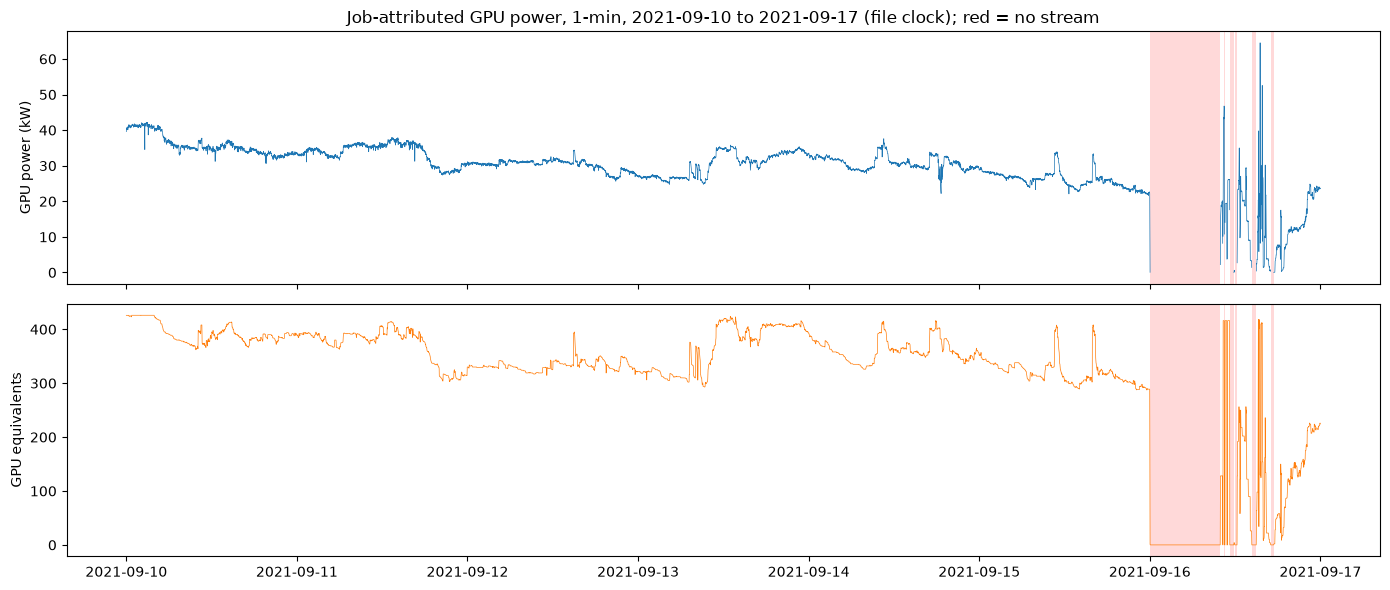

In [50]:
# Cell 40: First look at the time-weighted series (full week, empty minutes shaded)
import matplotlib.pyplot as plt

pdf = new.select("minute_local", "power_W", "n_gpu_equiv").to_pandas()
pdf["power_kW"] = pdf["power_W"] / 1000

# Contiguous runs of empty minutes
empty = pdf["power_W"].isna()
run_id = (empty != empty.shift()).cumsum()
runs = (pdf[empty].groupby(run_id[empty])["minute_local"].agg(["min", "max", "count"]))
print("empty runs:", len(runs))
print(runs.sort_values("count", ascending=False).head(10).to_string())

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(pdf["minute_local"], pdf["power_kW"], lw=0.5)
axes[0].set_ylabel("GPU power (kW)")
axes[1].plot(pdf["minute_local"], pdf["n_gpu_equiv"], lw=0.5, color="tab:orange")
axes[1].set_ylabel("GPU equivalents")
for _, r in runs.iterrows():
    for ax in axes:
        ax.axvspan(r["min"], r["max"], color="red", alpha=0.15, lw=0)
axes[0].set_title("Job-attributed GPU power, 1-min, 2021-09-10 to 2021-09-17 (file clock); red = no stream")
plt.tight_layout()
plt.show()

In [51]:
# Cell 41: Was the cluster down on 2021-09-16? Hourly job activity from slurm-log
import datetime as dt

H0 = int(dt.datetime(2021, 9, 15, 12, 0).timestamp())  # placeholder, replaced below with naive epoch
h0 = pl.datetime(2021, 9, 15, 12).dt.epoch("s")
h1 = pl.datetime(2021, 9, 17, 0).dt.epoch("s")
hours = pl.select(pl.int_range(h0, h1, 3600, dtype=pl.Int64).alias("h"))

all_jobs = (
    pl.read_csv(LOGCSV, infer_schema_length=0)
      .with_columns(
          pl.col("tres_alloc").str.extract(r"(?:^|,)100[12]=(\d+)", 1).cast(pl.Int64).alias("n_gpu"),
          *[pl.col(c).cast(pl.Int64) for c in ("id_job", "time_submit", "time_start", "time_end")],
      )
      .with_columns(
          log_to_file_clock(pl.col("time_submit")).alias("submit_fc"),
          log_to_file_clock(pl.col("time_start")).alias("start_fc"),
          log_to_file_clock(pl.col("time_end")).alias("end_fc"),
      )
)
has_file = pl.read_parquet(ROOT / "data/interim/gpu_file_index.parquet").select(
    pl.col("id_job").cast(pl.Int64)).unique().with_columns(pl.lit(True).alias("has_file"))
all_jobs = all_jobs.join(has_file, on="id_job", how="left").with_columns(pl.col("has_file").fill_null(False))

hmin, hmax = hours["h"].min(), hours["h"].max() + 3600
near = all_jobs.filter(((pl.col("start_fc") < hmax) & (pl.col("end_fc") > hmin)) |
                       pl.col("submit_fc").is_between(hmin, hmax))

x = hours.join(near, how="cross")
active = (pl.col("start_fc") < pl.col("h") + 3600) & (pl.col("end_fc") > pl.col("h"))
gpu = pl.col("n_gpu").is_not_null()
tab = (
    x.group_by("h").agg(
        active.sum().alias("active_all"),
        (active & gpu).sum().alias("active_gpu"),
        (active & gpu & pl.col("has_file")).sum().alias("active_gpu_with_file"),
        (active & gpu).cast(pl.Int64).mul(pl.col("n_gpu").fill_null(0)).sum().alias("gpus_alloc"),
        pl.col("submit_fc").is_between(pl.col("h"), pl.col("h") + 3599).sum().alias("submitted_all"),
    )
    .with_columns(pl.from_epoch("h").alias("hour_local"))
    .sort("h")
    .drop("h")
)
with pl.Config(tbl_rows=40):
    print(tab.select("hour_local", "active_all", "active_gpu", "active_gpu_with_file", "gpus_alloc", "submitted_all"))

shape: (36, 6)
┌─────────────────────┬────────────┬────────────┬─────────────────────┬────────────┬───────────────┐
│ hour_local          ┆ active_all ┆ active_gpu ┆ active_gpu_with_fil ┆ gpus_alloc ┆ submitted_all │
│ ---                 ┆ ---        ┆ ---        ┆ e                   ┆ ---        ┆ ---           │
│ datetime[μs]        ┆ u32        ┆ u32        ┆ ---                 ┆ i64        ┆ u32           │
│                     ┆            ┆            ┆ u32                 ┆            ┆               │
╞═════════════════════╪════════════╪════════════╪═════════════════════╪════════════╪═══════════════╡
│ 2021-09-15 12:00:00 ┆ 908        ┆ 245        ┆ 245                 ┆ 346        ┆ 286           │
│ 2021-09-15 13:00:00 ┆ 869        ┆ 212        ┆ 212                 ┆ 311        ┆ 199           │
│ 2021-09-15 14:00:00 ┆ 757        ┆ 208        ┆ 208                 ┆ 311        ┆ 120           │
│ 2021-09-15 15:00:00 ┆ 801        ┆ 288        ┆ 288                 ┆ 458 

In [52]:
# Cell 42: Cluster-wide idle gaps (no job of any kind running) over the whole log
iv = (
    all_jobs.filter(pl.col("end_fc") > pl.col("start_fc"))
            .select("start_fc", "end_fc")
            .sort("start_fc")
            .with_columns(pl.col("end_fc").cum_max().shift(1).alias("prev_max_end"))
)
gaps = (
    iv.filter(pl.col("start_fc") > pl.col("prev_max_end"))
      .with_columns(((pl.col("start_fc") - pl.col("prev_max_end")) / 60).alias("gap_min"))
      .filter(pl.col("gap_min") >= 10)
      .select(pl.from_epoch("prev_max_end").alias("gap_start_local"),
              pl.from_epoch("start_fc").alias("gap_end_local"),
              pl.col("gap_min").round(1))
      .sort("gap_start_local")
)
print("cluster-wide gaps >= 10 min:", gaps.height, "| total hours:", round(gaps["gap_min"].sum() / 60, 1))
with pl.Config(tbl_rows=50):
    print(gaps)
    

cluster-wide gaps >= 10 min: 19 | total hours: 126.9
shape: (19, 3)
┌─────────────────────┬─────────────────────┬─────────┐
│ gap_start_local     ┆ gap_end_local       ┆ gap_min │
│ ---                 ┆ ---                 ┆ ---     │
│ datetime[μs]        ┆ datetime[μs]        ┆ f64     │
╞═════════════════════╪═════════════════════╪═════════╡
│ 2021-01-21 00:02:20 ┆ 2021-01-21 14:45:30 ┆ 883.2   │
│ 2021-01-21 15:59:16 ┆ 2021-01-21 16:22:03 ┆ 22.8    │
│ 2021-03-02 00:01:00 ┆ 2021-03-02 18:24:48 ┆ 1103.8  │
│ 2021-03-02 19:09:53 ┆ 2021-03-02 19:47:07 ┆ 37.2    │
│ 2021-03-18 00:12:05 ┆ 2021-03-18 14:03:02 ┆ 831.0   │
│ 2021-03-29 12:21:13 ┆ 2021-03-29 15:04:49 ┆ 163.6   │
│ 2021-04-15 00:03:59 ┆ 2021-04-15 12:03:02 ┆ 719.0   │
│ 2021-04-15 12:08:24 ┆ 2021-04-15 12:40:10 ┆ 31.8    │
│ 2021-04-15 13:09:53 ┆ 2021-04-15 16:15:41 ┆ 185.8   │
│ 2021-05-20 00:00:17 ┆ 2021-05-20 09:42:37 ┆ 582.3   │
│ 2021-06-17 00:15:22 ┆ 2021-06-17 12:05:38 ┆ 710.3   │
│ 2021-06-17 13:28:46 ┆ 2021-06-17 1

In [53]:
# Cell 43: Sizes of pipeline inputs and outputs for README
def dir_size(p, pattern="*"):
    files = [f for f in p.glob(pattern) if f.is_file()]
    return len(files), sum(f.stat().st_size for f in files)

files_idx = pl.read_parquet(ROOT / "data/interim/dev_window_files.parquet")
print(f"input (raw CSV, downloaded then deleted): {files_idx.height:,} files, "
      f"{files_idx['size'].sum() / 2**30:.2f} GiB")

n, b = dir_size(STREAMS, "*.parquet")
print(f"stream Parquets: {n:,} files, {b / 2**20:.1f} MiB")

for f in ["series_dev.parquet", "series_dev_v1_unweighted.parquet"]:
    p = ROOT / "data/processed" / f
    print(f"{f}: {p.stat().st_size / 2**10:.1f} KiB")

print("compression ratio raw -> streams: "
      f"{files_idx['size'].sum() / b:,.0f}x")

input (raw CSV, downloaded then deleted): 7,435 files, 134.54 GiB
stream Parquets: 7,435 files, 111.2 MiB
series_dev.parquet: 559.8 KiB
series_dev_v1_unweighted.parquet: 526.2 KiB
compression ratio raw -> streams: 1,239x


In [54]:
# Cell 44: Measure pipeline run times and sizes exactly, then append a section to README.md
import re, time, calendar, importlib.util
from datetime import datetime

README = ROOT / "README.md"
MARKER = "## Building the GPU power series"

# 1) Run times from the logs (last progress line of each run)
def elapsed_and_rate(log_path):
    lines = [l for l in log_path.read_text().splitlines() if "elapsed" in l and "done=" in l]
    last = lines[-1]
    el = float(re.search(r"elapsed\s+([\d.]+)\s+min", last).group(1))
    rate = float(re.search(r"([\d.]+)\s+MiB/s", last).group(1))
    failed = int(re.search(r"failed=([\d,]+)", last).group(1).replace(",", ""))
    return el, rate, failed

run1_min, run1_rate, run1_failed = elapsed_and_rate(ROOT / "data/interim/build_dev.log")
retry_min, retry_rate, retry_failed = elapsed_and_rate(ROOT / "data/interim/build_dev_retry.log")
print(f"first run: {run1_min} min, {run1_rate} MiB/s, failed={run1_failed}")
print(f"retry:     {retry_min} min, {retry_rate} MiB/s, failed={retry_failed}")

# 2) Time the series rebuild by calling build_series() from the script itself (no file is written)
spec = importlib.util.spec_from_file_location("build_series_mod", SCRIPT)
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)

t0 = calendar.timegm(datetime(2021, 9, 10).timetuple())   # file clock stored as naive epoch
t1 = calendar.timegm(datetime(2021, 9, 17).timetuple())
saved = pl.read_parquet(SERIES)
assert saved["minute_epoch"].min() == t0 and saved["minute_epoch"].max() == t1 - 60, "window bounds mismatch"

tic = time.perf_counter()
rebuilt = mod.build_series(STREAMS, t0, t1)
rebuild_s = time.perf_counter() - tic
identical = rebuilt.equals(saved)
print(f"series rebuild: {rebuild_s:.1f} s | identical to saved file: {identical}")
assert identical, "rebuilt series differs from the saved file; do not write README"

# 3) Sizes
files_idx = pl.read_parquet(ROOT / "data/interim/dev_window_files.parquet")
raw_gib = files_idx["size"].sum() / 2**30
n_streams = len(list(STREAMS.glob("*.parquet")))
streams_mib = sum(f.stat().st_size for f in STREAMS.glob("*.parquet")) / 2**20
series_kib = SERIES.stat().st_size / 2**10
n_empty = saved.filter(pl.col("n_gpu_streams") == 0).height

# 4) README section
section = rf"""
{MARKER}

One command builds the 1-minute aggregate series from the raw MIT Supercloud GPU files.
Files are downloaded, aggregated per minute and deleted immediately, so disk use stays small.
The run is resumable: re-running the same command skips finished files and retries failed ones.
A VPN connection is required for downloads (see `docs/data_quality.md`).

```bash
caffeinate -i /opt/miniconda3/envs/dcpower/bin/python -u src/data/build_series.py \
  --files data/interim/dev_window_files.parquet \
  --stream-dir data/interim/streams_dev \
  --tmp-dir data/interim/_tmp_raw \
  --out data/processed/series_dev.parquet \
  --win-start 2021-09-10 --win-end 2021-09-17 --workers 8
```

For multi-hour runs, start it from Terminal with `caffeinate -i nohup ... > log 2>&1 &`.

### Development window (2021-09-10 to 2021-09-17, file clock = America/New_York)

| Item | Value |
|---|---|
| Input | {files_idx.height:,} GPU files, {raw_gib:.2f} GiB raw CSV (downloaded, then deleted) |
| Intermediate | {n_streams:,} per-file stream Parquets, {streams_mib:.1f} MiB (`data/interim/streams_dev/`) |
| Output | `data/processed/series_dev.parquet`, {saved.height:,} rows, {series_kib:.1f} KiB |
| First pass | {run1_min:.1f} min at {run1_rate:.2f} MiB/s with 8 workers; {run1_failed} files failed with transient SSL errors |
| Retry | {retry_min:.1f} min at {retry_rate:.2f} MiB/s; {retry_failed} failures |
| Series rebuild from existing streams | {rebuild_s:.1f} s (measured; output identical to the saved file) |

### Output columns

| Column | Meaning |
|---|---|
| `minute_epoch`, `minute_local` | Minute start in the file clock (New York local time) |
| `power_W` | Time-weighted sum of GPU power over all job streams (energy / 60 s) |
| `util_gpu_mean`, `util_mem_mean`, `temp_gpu_mean`, `temp_mem_mean` | Time-weighted means over streams |
| `mem_used_sum`, `mem_free_sum` | Time-weighted sums over streams (MiB) |
| `n_gpu_equiv` | Sum of stream weights (full-GPU equivalents) |
| `n_gpu_streams` | Raw count of distinct (file, gpu_index) streams in the minute |
| `n_edge_streams` | Streams in their first or last minute (partial coverage) |

Minutes with no job stream ({n_empty:,} in the development window) have `n_gpu_streams = 0` and null metrics.
The aggregation rule and all data issues are documented in `docs/data_quality.md`.
"""

existing = README.read_text() if README.exists() else ""
if MARKER in existing:
    print("\nREADME already contains this section; nothing written")
else:
    README.write_text(existing.rstrip("\n") + "\n" + section)
    print(f"\nappended {len(section.splitlines())} lines to {README}")

first run: 368.4 min, 5.7 MiB/s, failed=310
retry:     37.2 min, 5.24 MiB/s, failed=0
series rebuild: 1.8 s | identical to saved file: True

appended 44 lines to /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/README.md


In [55]:
# Cell 45: Classify empty minutes: cluster-wide outage vs cluster up with no GPU job
gaps_all = (
    iv.filter(pl.col("start_fc") > pl.col("prev_max_end"))
      .select(pl.col("prev_max_end").alias("g0"), pl.col("start_fc").alias("g1"))
      .filter((pl.col("g1") > t0) & (pl.col("g0") < t1))
)

empty_min = saved.filter(pl.col("n_gpu_streams") == 0).select("minute_epoch", "minute_local")

# A minute counts as outage if the whole minute [m, m+60) lies inside a cluster-wide gap
cls = (
    empty_min.join(gaps_all, how="cross")
             .with_columns(((pl.col("g0") <= pl.col("minute_epoch")) &
                            (pl.col("g1") >= pl.col("minute_epoch") + 60)).alias("in_gap"))
             .group_by("minute_epoch", "minute_local").agg(pl.col("in_gap").any())
             .sort("minute_epoch")
)
print("empty minutes:", cls.height)
print(cls.group_by("in_gap").len())

# Runs of empty minutes that are NOT inside a cluster-wide gap
not_gap = cls.filter(~pl.col("in_gap")).with_columns(
    (pl.col("minute_epoch").diff().fill_null(60) != 60).cum_sum().alias("run")
)
print(not_gap.group_by("run").agg(
    pl.col("minute_local").min().alias("from"), pl.col("minute_local").max().alias("to"), pl.len().alias("n")
).sort("from"))

empty minutes: 722
shape: (2, 2)
┌────────┬─────┐
│ in_gap ┆ len │
│ ---    ┆ --- │
│ bool   ┆ u32 │
╞════════╪═════╡
│ false  ┆ 48  │
│ true   ┆ 674 │
└────────┴─────┘
shape: (4, 4)
┌─────┬─────────────────────┬─────────────────────┬─────┐
│ run ┆ from                ┆ to                  ┆ n   │
│ --- ┆ ---                 ┆ ---                 ┆ --- │
│ u32 ┆ datetime[μs]        ┆ datetime[μs]        ┆ u32 │
╞═════╪═════════════════════╪═════════════════════╪═════╡
│ 0   ┆ 2021-09-16 10:30:00 ┆ 2021-09-16 10:34:00 ┆ 5   │
│ 1   ┆ 2021-09-16 11:15:00 ┆ 2021-09-16 11:23:00 ┆ 9   │
│ 2   ┆ 2021-09-16 14:51:00 ┆ 2021-09-16 14:58:00 ┆ 8   │
│ 3   ┆ 2021-09-16 17:00:00 ┆ 2021-09-16 17:25:00 ┆ 26  │
└─────┴─────────────────────┴─────────────────────┴─────┘


In [56]:
# Cell 46: Write src/data/build_log_features.py (outage flags + log covariates)
import py_compile

SCRIPT2 = ROOT / "src/data/build_log_features.py"

CODE = r'''"""Build per-minute features from the Slurm log and attach them to the GPU power series.

All times are in the file clock (America/New_York wall clock stored as naive epoch seconds).
Slurm log times are true UTC and are converted with log_to_file_clock().

Added columns:
  outage           minute lies entirely inside a cluster-wide gap (no job of any kind running)
  maint_day        local calendar day of a long cluster-wide gap (>= --outage-min-hours);
                   the day is the date of (gap start + 2 h), so a gap starting just before
                   midnight counts for the next day
  active_jobs      jobs of any kind running at the end of the minute
  active_gpu_jobs  GPU jobs running at the end of the minute
  gpus_alloc       GPUs allocated to running GPU jobs at the end of the minute
  queued_jobs      jobs submitted but not yet started at the end of the minute
  queued_gpu_jobs  same, GPU jobs only
State variables are sampled at the minute end (t + 60 s), the moment the minute's power value
becomes available, so they carry no information from after the minute.

Empty minutes (n_gpu_streams == 0):
  - during an outage: power and all metrics stay null (cluster down; masked in modelling);
  - cluster up but no GPU job: power_W, mem_used_sum, mem_free_sum and n_gpu_equiv are set
    to 0 (true job-attributed value); utilization and temperature means stay null
    (undefined without GPUs).
"""
import argparse
from pathlib import Path

import numpy as np
import polars as pl

GPU_RE = r"(?:^|,)100[12]=(\d+)"


def log_to_file_clock(col: pl.Expr) -> pl.Expr:
    return (pl.from_epoch(col, time_unit="s").dt.replace_time_zone("UTC")
            .dt.convert_time_zone("America/New_York").dt.replace_time_zone(None).dt.epoch("s"))


def load_log(path: Path) -> pl.DataFrame:
    return (
        pl.read_csv(path, infer_schema_length=0,
                    columns=["id_job", "tres_alloc", "time_submit", "time_start", "time_end"])
        .with_columns(
            pl.col("tres_alloc").str.extract(GPU_RE, 1).cast(pl.Int64).alias("n_gpu"),
            *[pl.col(c).cast(pl.Int64) for c in ("time_submit", "time_start", "time_end")],
        )
        .with_columns(
            log_to_file_clock(pl.col("time_submit")).alias("submit_fc"),
            log_to_file_clock(pl.col("time_start")).alias("start_fc"),
            log_to_file_clock(pl.col("time_end")).alias("end_fc"),
        )
    )


def count_at(t: np.ndarray, starts: np.ndarray, ends: np.ndarray, weights=None) -> np.ndarray:
    """Number (or weighted sum) of intervals with start <= t < end, for each instant t."""
    os_, oe = np.argsort(starts, kind="stable"), np.argsort(ends, kind="stable")
    s, e = starts[os_], ends[oe]
    i_s, i_e = np.searchsorted(s, t, side="right"), np.searchsorted(e, t, side="right")
    if weights is None:
        return i_s - i_e
    ws = np.concatenate([[0], np.cumsum(weights[os_])])
    we = np.concatenate([[0], np.cumsum(weights[oe])])
    return ws[i_s] - we[i_e]


def cluster_gaps(starts: np.ndarray, ends: np.ndarray):
    """Intervals (g0, g1) during which no job of any kind is running."""
    o = np.argsort(starts, kind="stable")
    s, e = starts[o], ends[o]
    cmax = np.maximum.accumulate(e)
    idx = np.nonzero(s[1:] > cmax[:-1])[0]
    return cmax[:-1][idx], s[1:][idx]


def main() -> None:
    ap = argparse.ArgumentParser(description="Attach Slurm-log features to the GPU power series.")
    ap.add_argument("--log", type=Path, required=True, help="slurm-log.csv")
    ap.add_argument("--series", type=Path, required=True, help="output of build_series.py")
    ap.add_argument("--out", type=Path, required=True)
    ap.add_argument("--outage-min-hours", type=float, default=6.0,
                    help="minimum cluster-wide gap length that marks a maintenance day")
    a = ap.parse_args()

    log = load_log(a.log)
    ran = log.filter(pl.col("end_fc") > pl.col("start_fc"))
    print(f"log rows: {log.height:,}; with end > start: {ran.height:,}")

    # Cluster-wide gaps and maintenance days (whole log)
    g0, g1 = cluster_gaps(ran["start_fc"].to_numpy(), ran["end_fc"].to_numpy())
    long_ = (g1 - g0) >= a.outage_min_hours * 3600
    maint_dates = (pl.DataFrame({"g": g0[long_] + 7200})
                   .select(pl.from_epoch("g").dt.date().alias("d"))["d"].unique().sort())
    print(f"cluster-wide gaps: {len(g0):,}; long (>= {a.outage_min_hours} h): {int(long_.sum())}")
    print("maintenance days in the whole log:", [str(d) for d in maint_dates])

    s = pl.read_parquet(a.series)
    m = s["minute_epoch"].to_numpy()
    t_end = m + 60

    # Outage: minute [m, m+60) entirely inside one gap (gaps are disjoint and sorted)
    k = np.searchsorted(g0, m, side="right") - 1
    outage = (k >= 0) & (g1[np.clip(k, 0, None)] >= m + 60)

    gpu = ran.filter(pl.col("n_gpu").is_not_null())
    queued_all = log.filter(pl.col("start_fc") >= pl.col("submit_fc"))
    queued_gpu = queued_all.filter(pl.col("n_gpu").is_not_null())

    feat = pl.DataFrame({
        "minute_epoch": m,
        "outage": outage,
        "active_jobs": count_at(t_end, ran["start_fc"].to_numpy(), ran["end_fc"].to_numpy()),
        "active_gpu_jobs": count_at(t_end, gpu["start_fc"].to_numpy(), gpu["end_fc"].to_numpy()),
        "gpus_alloc": count_at(t_end, gpu["start_fc"].to_numpy(), gpu["end_fc"].to_numpy(),
                               gpu["n_gpu"].to_numpy()),
        "queued_jobs": count_at(t_end, queued_all["submit_fc"].to_numpy(), queued_all["start_fc"].to_numpy()),
        "queued_gpu_jobs": count_at(t_end, queued_gpu["submit_fc"].to_numpy(), queued_gpu["start_fc"].to_numpy()),
    })

    no_gpu_up = (pl.col("n_gpu_streams") == 0) & ~pl.col("outage")
    out = (
        s.join(feat, on="minute_epoch", how="left")
        .with_columns(pl.col("minute_local").dt.date().is_in(maint_dates.implode()).alias("maint_day"))
        .with_columns([
            pl.when(no_gpu_up).then(pl.lit(0.0)).otherwise(pl.col(c)).alias(c)
            for c in ("power_W", "mem_used_sum", "mem_free_sum", "n_gpu_equiv")
        ])
    )

    conflict = out.filter(pl.col("outage") & (pl.col("n_gpu_streams") > 0)).height
    print(f"minutes: {out.height:,}; outage: {int(out['outage'].sum()):,}; "
          f"cluster up, no GPU job (set to 0): {out.filter(no_gpu_up).height:,}; "
          f"maint_day: {int(out['maint_day'].sum()):,}")
    print(f"null power_W after rules: {out['power_W'].null_count():,}; "
          f"outage minutes with GPU streams (should be 0): {conflict}")
    print(f"gpus_alloc max: {out['gpus_alloc'].max()} (cluster has 448 GPUs)")

    a.out.parent.mkdir(parents=True, exist_ok=True)
    out.write_parquet(a.out)
    print(f"written: {a.out} ({out.height:,} rows, {len(out.columns)} columns)")


if __name__ == "__main__":
    main()
'''

if SCRIPT2.exists() and SCRIPT2.read_text() == CODE:
    print("script already up to date; nothing written")
else:
    if SCRIPT2.exists():
        print("WARNING: overwriting existing", SCRIPT2)
    SCRIPT2.write_text(CODE)
    print("written:", SCRIPT2)

py_compile.compile(str(SCRIPT2), doraise=True)
print("compiled OK | lines:", len(SCRIPT2.read_text().splitlines()), "| mtime:", mtime(SCRIPT2))

written: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/src/data/build_log_features.py
compiled OK | lines: 144 | mtime: 2026-10-02 07:57:57


In [57]:
# Cell 47: Inspect the 2 minutes flagged as outage that still have GPU streams
feat = pl.read_parquet(ROOT / "data/processed/series_dev_features.parquet")
bad = feat.filter(pl.col("outage") & (pl.col("n_gpu_streams") > 0))
print(bad.select("minute_local", "power_W", "n_gpu_streams", "n_edge_streams", "n_gpu_equiv",
                 "active_jobs", "active_gpu_jobs"))

# The gap(s) containing these minutes, and the streams that wrote samples there
for m in bad["minute_epoch"].to_list():
    g = gaps_all.filter((pl.col("g0") <= m) & (pl.col("g1") >= m + 60))
    print("\nminute", dt.datetime.utcfromtimestamp(m), "| gap:",
          dt.datetime.utcfromtimestamp(g["g0"][0]), "->", dt.datetime.utcfromtimestamp(g["g1"][0]),
          f"({(g['g1'][0] - g['g0'][0]) / 60:.1f} min)")
    rows = all_st.filter(pl.col("minute_epoch") == m)
    ids = rows["file"].str.extract(r"^(\d+)-", 1).cast(pl.Int64).unique()
    print(rows.select("file", "gpu_index", "n_samples"))
    print(all_jobs.filter(pl.col("id_job").is_in(ids.implode())).select(
        "id_job", pl.from_epoch("start_fc").alias("log_start"), pl.from_epoch("end_fc").alias("log_end"), "n_gpu"))
    

shape: (2, 7)
┌──────────────┬────────────┬──────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ minute_local ┆ power_W    ┆ n_gpu_stream ┆ n_edge_stre ┆ n_gpu_equiv ┆ active_jobs ┆ active_gpu_ │
│ ---          ┆ ---        ┆ s            ┆ ams         ┆ ---         ┆ ---         ┆ jobs        │
│ datetime[μs] ┆ f64        ┆ ---          ┆ ---         ┆ f64         ┆ i64         ┆ ---         │
│              ┆            ┆ i64          ┆ i64         ┆             ┆             ┆ i64         │
╞══════════════╪════════════╪══════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ 2021-09-16   ┆ 134.191122 ┆ 35           ┆ 33          ┆ 4.308792    ┆ 0           ┆ 0           │
│ 00:01:00     ┆            ┆              ┆             ┆             ┆             ┆             │
│ 2021-09-16   ┆ 49.563226  ┆ 2            ┆ 2           ┆ 1.839572    ┆ 0           ┆ 0           │
│ 00:02:00     ┆            ┆              ┆             ┆             ┆     

In [58]:
# Cell 48: Patch build_log_features.py: outage = cluster gap AND no GPU telemetry
code = SCRIPT2.read_text()
if '"cluster_gap": outage,' in code:
    print("already patched; nothing done")
else:
    edits = [
        ('"outage": outage,', '"cluster_gap": outage,'),
        ('        s.join(feat, on="minute_epoch", how="left")\n',
         '        s.join(feat, on="minute_epoch", how="left")\n'
         '        .with_columns((pl.col("cluster_gap") & (pl.col("n_gpu_streams") == 0)).alias("outage"))\n'),
        ('    conflict = out.filter(pl.col("outage") & (pl.col("n_gpu_streams") > 0)).height',
         '    conflict = out.filter(pl.col("cluster_gap") & (pl.col("n_gpu_streams") > 0)).height'),
        ('f"outage minutes with GPU streams (should be 0): {conflict}"',
         'f"cluster-gap minutes with GPU telemetry (kept, not outage): {conflict}"'),
        ('  outage           minute lies entirely inside a cluster-wide gap (no job of any kind running)\n',
         '  cluster_gap      minute lies entirely inside a cluster-wide gap in the log (no job of any kind)\n'
         '  outage           cluster_gap and no GPU telemetry in the minute; GPU files can keep recording\n'
         '                   for up to a few minutes after jobs are killed at a maintenance start, and\n'
         '                   telemetry takes precedence over the log\n'),
    ]
    for old, new in edits:
        assert code.count(old) == 1, f"pattern not found exactly once: {old[:60]!r}"
        code = code.replace(old, new)
    SCRIPT2.write_text(code)
    py_compile.compile(str(SCRIPT2), doraise=True)
    print("patched and compiled OK | lines:", len(code.splitlines()), "| mtime:", mtime(SCRIPT2))

patched and compiled OK | lines: 148 | mtime: 2026-10-02 08:00:01


In [59]:
# Cell 49: Sanity checks of the log covariates
feat = pl.read_parquet(ROOT / "data/processed/series_dev_features.parquet")
cov = ["active_jobs", "active_gpu_jobs", "gpus_alloc", "queued_jobs", "queued_gpu_jobs"]
print("columns:", feat.columns)
print("\nnull counts:", feat.select(cov).null_count().row(0))
print(feat.select(cov).describe())

# Log (gpus_alloc) vs files (n_gpu_equiv), normal days only
nd = feat.filter(~pl.col("maint_day"))
d = nd.with_columns((pl.col("gpus_alloc") - pl.col("n_gpu_equiv")).alias("diff"))
print("\nnormal-day minutes:", nd.height)
print(d.select(
    pl.corr("gpus_alloc", "n_gpu_equiv").alias("corr_alloc_vs_equiv"),
    pl.col("diff").mean().alias("mean_diff"),
    pl.col("diff").quantile(0.01).alias("q01_diff"),
    pl.col("diff").quantile(0.99).alias("q99_diff"),
    (pl.col("diff") / pl.col("gpus_alloc")).mean().alias("mean_rel_diff"),
))

# Simultaneous correlation of power with each covariate (normal days)
print(nd.select([pl.corr("power_W", c).alias(c) for c in cov + ["n_gpu_equiv", "util_gpu_mean"]]))

columns: ['minute_epoch', 'power_W', 'util_gpu_mean', 'util_mem_mean', 'temp_gpu_mean', 'temp_mem_mean', 'mem_used_sum', 'mem_free_sum', 'n_gpu_equiv', 'n_gpu_streams', 'n_edge_streams', 'minute_local', 'cluster_gap', 'active_jobs', 'active_gpu_jobs', 'gpus_alloc', 'queued_jobs', 'queued_gpu_jobs', 'outage', 'maint_day']

null counts: (0, 0, 0, 0, 0)
shape: (9, 6)
┌────────────┬─────────────┬─────────────────┬────────────┬─────────────┬─────────────────┐
│ statistic  ┆ active_jobs ┆ active_gpu_jobs ┆ gpus_alloc ┆ queued_jobs ┆ queued_gpu_jobs │
│ ---        ┆ ---         ┆ ---             ┆ ---        ┆ ---         ┆ ---             │
│ str        ┆ f64         ┆ f64             ┆ f64        ┆ f64         ┆ f64             │
╞════════════╪═════════════╪═════════════════╪════════════╪═════════════╪═════════════════╡
│ count      ┆ 10080.0     ┆ 10080.0         ┆ 10080.0    ┆ 10080.0     ┆ 10080.0         │
│ null_count ┆ 0.0         ┆ 0.0             ┆ 0.0        ┆ 0.0         ┆ 0.0    

In [60]:
# Cell 50: Inspect labelled_jobids.csv and labelled_job_stats.csv
RAW = ROOT / "data/raw"
for f in ["labelled_job_stats.csv", "labelled_jobids.csv"]:
    df = pl.read_csv(RAW / f, infer_schema_length=10000)
    print(f"\n=== {f}: {df.shape} ===")
    print(df.schema)
    print(df.head(8))

lab = pl.read_csv(RAW / "labelled_jobids.csv", infer_schema_length=10000)
# Which column holds the job id, and how many labelled jobs fall in the development window?
id_col = next(c for c in lab.columns if "id" in c.lower())
lab_ids = lab.with_columns(pl.col(id_col).cast(pl.Int64, strict=False))
in_win = all_jobs.filter((pl.col("start_fc") < t1) & (pl.col("end_fc") > t0) & pl.col("n_gpu").is_not_null())
hit = lab_ids.join(in_win.select("id_job"), left_on=id_col, right_on="id_job", how="inner")
print(f"\nlabelled jobs: {lab.height:,} | id column used: {id_col!r} | "
      f"overlapping the dev window (GPU jobs): {hit.height:,} of {in_win.height:,} GPU jobs in window")
other = [c for c in lab.columns if c != id_col]
if other:
    print(lab.group_by(other[0]).len().sort("len", descending=True).head(15))


=== labelled_job_stats.csv: (26, 2) ===
Schema([('model', String), ('count', Int64)])
shape: (8, 2)
┌────────┬───────┐
│ model  ┆ count │
│ ---    ┆ ---   │
│ str    ┆ i64   │
╞════════╪═══════╡
│ U3-128 ┆ 165   │
│ U3-32  ┆ 165   │
│ U3-64  ┆ 159   │
│ U4-128 ┆ 157   │
│ U4-32  ┆ 163   │
│ U4-64  ┆ 158   │
│ U5-128 ┆ 148   │
│ U5-32  ┆ 158   │
└────────┴───────┘

=== labelled_jobids.csv: (3430, 2) ===
Schema([('id_job', Int64), ('model', String)])
shape: (8, 2)
┌────────────────┬─────────┐
│ id_job         ┆ model   │
│ ---            ┆ ---     │
│ i64            ┆ str     │
╞════════════════╪═════════╡
│ 25664193915111 ┆ dimenet │
│ 42371679622969 ┆ schnet  │
│ 64971010680493 ┆ conv    │
│ 75737118513639 ┆ pna     │
│ 68345852389234 ┆ dimenet │
│ 55635858367332 ┆ schnet  │
│ 15609644815926 ┆ conv    │
│ 32008563524845 ┆ dimenet │
└────────────────┴─────────┘

labelled jobs: 3,430 | id column used: 'id_job' | overlapping the dev window (GPU jobs): 6 of 5,379 GPU jobs in window
shape:

In [62]:
# Cell 51: Write docs/data_quality.md (English), with numbers measured from the data
DQ = ROOT / "docs/data_quality.md"
DQ.parent.mkdir(parents=True, exist_ok=True)

# Measured numbers
st_nulls = (pl.scan_parquet(str(STREAMS / "*.parquet"))
              .select(pl.len().alias("rows"),
                      *[pl.col(c).null_count().alias(c) for c in
                        ("power_W", "util_gpu", "util_mem", "temp_gpu", "temp_mem", "mem_used", "mem_free")])
              .collect())
r = st_nulls.row(0, named=True)
null_txt = ", ".join(f"`{c}` {r[c]:,}" for c in st_nulls.columns if c != "rows")
print("stream rows:", r["rows"], "|", null_txt)

f = feat
n_outage = int(f["outage"].sum()); n_zero = f.filter((pl.col("n_gpu_streams") == 0) & ~pl.col("outage")).height
n_tail = f.filter(pl.col("cluster_gap") & (pl.col("n_gpu_streams") > 0)).height
e_old = pl.read_parquet(ROOT / "data/processed/series_dev_v1_unweighted.parquet")["power_W"].sum() / 60000; e_new = pl.read_parquet(SERIES)["power_W"].sum() / 60000
doc = f"""# Data quality report: MIT Supercloud GPU power series

Scope: development window 2021-09-10 to 2021-09-17 (file clock), built with
`src/data/build_series.py` and `src/data/build_log_features.py`. Numbers below refer to this
window unless stated otherwise. Statements marked *unverified* are empirical observations whose
mechanism has not been confirmed from documentation.

## 1. Sources

- `slurm-log.csv`: 395,914 jobs, 29 columns; times are Unix seconds in true UTC. GPU jobs are
  identified from `tres_alloc` codes 1001/1002 (`gres_used` is null in all rows): 99,344 GPU jobs.
- `gpu/`: 109,946 files, 2,269.5 GiB. One file holds one node of one job, with all GPUs of that
  node interleaved; `nvidia-smi` sampling about every 0.103 to 0.107 s.
- Development window: 7,435 files, 134.54 GiB raw CSV, aggregated to 7,435 per-file stream
  Parquets (111.2 MiB) and one 1-minute series of 10,080 rows.

## 2. Time frame

**Rule (empirical):** Slurm log times are UTC; GPU file timestamps are America/New_York wall-clock
times stored as epoch seconds. Log times are converted with `log_to_file_clock()`
(UTC to New York local, then dropped time zone). The series is in the file clock (`minute_local`).

**Evidence:**
- On 25 files across February to October and both sides of the DST change, the residual between
  converted log times and file times is at most 1.9 s at job start and 9.3 s at job end
  (means 0.7 s and 1.2 s).
- All long cluster-wide outages in the log start within 15 minutes after local midnight in the
  file clock (Section 7), which is consistent with scheduled maintenance at local midnight.
- GPUs allocated according to the log and GPU equivalents observed in the files agree closely on
  normal days (correlation 0.997, mean difference 0.8 GPUs, 0.2%).
- The mechanism behind the offset is *unverified*.

**Consequences:** the local hour 02:00 to 02:59 on 14 March 2021 does not exist (one-hour gap in a
full-length series); the ambiguous November hour is outside the data range.

**Exception (new):** when jobs are killed at the start of a maintenance outage, GPU files can keep
recording for up to about 3 minutes after the job end in the log (observed on 2021-09-16:
log ends 00:00:24 to 00:00:27, telemetry until about 00:02:55, at idle power). The 9.3 s bound
above holds for normal job ends only.

## 3. Identifiers and streams

- File name: `<id_job>-r<digits>-n<digits>.csv`. `id_job` matches the log for every file.
- **Node id is the combined `r...-n...` string**, matching entries of the log's `nodelist`
  (e.g. `r6760045-n386398`). The `r...` part alone is not unique across nodes. The meaning of the
  `n...` part is *unverified*.
- A stream is one `(file, gpu_index)` pair. A physical GPU is `(node, gpu_index)`; with this key
  the maximum number of physical GPUs active in one minute is 418 (cluster: 448 GPUs).

## 4. Sampling

- About 560 samples per fully covered minute, not 600; per-stream medians range from 539 to 581
  (1st to 99th percentile), so a single global constant is not accurate.
- Interior minutes (job running the whole minute) occasionally have fewer samples
  (minimum 287; 0.1% quantile 461): irregular sampling, not missing activity.
- Non-numeric values are read with `strict=False`. Null per-minute means in the stream Parquets
  ({r['rows']:,} stream-minute rows): {null_txt}.

## 5. Aggregation rule (time-weighted)

**Problem found:** the first version summed per-stream minute means. When one GPU switches from
one job to the next within a minute, both streams counted as a full minute, so power was counted
up to twice. Raw stream counts reached 540 in one minute, above the 448 GPUs of the cluster.
Example: 2021-09-16 15:32, when a 410-GPU group of jobs ended about 5 s into the minute:
unweighted 49.4 kW, time-weighted 8.2 kW.

**Rule now used:** each stream-minute has weight 1 for interior minutes and
`min(n_samples / full, 1)` for a stream's first and last minute, where `full` is the median
sample count over that stream's interior minutes (global median as fallback).
`power_W` = weighted sum (energy / 60 s); utilization and temperature are weighted means;
memory is a weighted sum. `n_gpu_equiv` (sum of weights) peaks at 426.

**Effect:** 3,764 minutes changed, but the mean change is small (energy over the week
{e_old:,.1f} kWh unweighted vs {e_new:,.1f} kWh weighted, {100 * (e_new - e_old) / e_old:.2f}%).
The error was concentrated in job-turnover minutes, exactly where ramps matter. This rule
replaces the earlier plan of a sensitivity check that drops or keeps edge minutes.
The unweighted series is kept as `data/processed/series_dev_v1_unweighted.parquet` for comparison.

## 6. Download failures and coverage

- First pass: 310 of 7,435 files failed, all with `SSLEOFError` (transient network or VPN drops).
  Partial downloads were deleted and the files retried: 0 failures. Run-1 failures are kept in
  `data/interim/streams_dev/_failures_run1.csv`.
- 1,168 GPU jobs in the log (about 1.2%) have no GPU file (cause *unverified*). Consistent with
  this, GPUs allocated in the log exceed GPU equivalents in the files by 0.8 on average.
- Rebuilding the series from existing streams reproduces the saved file exactly (1.8 s).

## 7. Cluster outages and maintenance days

From the log, the cluster had 42 cluster-wide gaps (no job of any kind running); 9 last at least
6 hours and start around local midnight, mostly on the third Thursday of a month:
2021-01-21, 2021-03-02, 2021-03-18, 2021-04-15, 2021-05-20, 2021-06-17, 2021-07-15, 2021-08-10,
2021-09-16 (about 127 hours in gaps of 10 minutes or more). An unscheduled-looking midday gap of
2.7 h occurred on 2021-03-29. That the long outages are scheduled maintenance is *unverified*
(no official schedule seen).

After an outage, the cluster runs a few very large jobs from one user for several hours
(likely post-maintenance tests, *unverified*) before normal load returns. On 2021-09-16 normal
operation resumed around 18:00.

**Decision on empty minutes (minutes with no GPU stream):**

| Case | Minutes | `power_W` | Reason |
|---|---|---|---|
| Outage: inside a cluster-wide gap and no GPU telemetry | {n_outage} | null | Cluster down; zero would create artificial ramps of about 30 kW. Masked in modelling. |
| Cluster up, no GPU job | {n_zero} | 0 | True job-attributed power, not missing data. |

Flags: `cluster_gap` (log only), `outage` (cluster gap and no telemetry; {n_tail} minutes are in a
cluster gap but still have telemetry and keep their values), `maint_day` (the whole local day of
a gap of at least 6 h, dated by gap start + 2 h). Maintenance days are excluded from the ramp
threshold and reported separately in evaluation. If the schedule is known in advance,
`maint_day` is a legitimate calendar covariate.

## 8. Peak power

The maximum is 64.5 kW at 2021-09-16 15:31, from 410 GPUs at about 157 W each. The log confirms
exactly 410 allocated GPUs in 4 jobs of one user and one array job (one job with 384 GPUs on
192 nodes). The peak is real but occurs in the post-maintenance period, not in normal operation.
The 99th percentile is about 41 kW. The dataset paper reports an aggregate peak of about 45 kW for
the whole period; the reason for the difference is *unverified* (possibly a different
aggregation or treatment of this period).

## 9. Target definition

The series is **job-attributed GPU power**: GPUs are recorded only while allocated to a job.
Idle GPUs outside jobs are absent, so this is not facility or node power. Idle GPUs inside jobs
draw about 27 to 47 W (baseline differs between files; cause *unverified*).

## 10. Log covariates

`active_jobs`, `active_gpu_jobs`, `gpus_alloc`, `queued_jobs`, `queued_gpu_jobs` are sampled at
the end of each minute (the moment its power value is complete), so they contain no information
from after the minute. Same-minute correlation with power on normal days: active GPU jobs 0.89,
allocated GPUs 0.88, queued GPU jobs 0.28, all active jobs 0.07. Only lagged values may be used
for forecasting.

## 11. Labelled jobs

`labelled_jobids.csv` labels 3,430 jobs with 26 model types (CNNs, BERT variants, U-Nets, graph
networks). Only 6 of 5,379 GPU jobs in the development window are labelled, so model type is not
used as a covariate for the aggregate series.

## 12. Correction history

- Week 2, cells 9 and 10: the time relationship was first interpreted the wrong way round, and
  cells 14, 16, 17 and 20 used a conversion 8 hours off. Caught in cell 22, fixed in cell 24.
  The daily tables of cells 14, 16 and 17 must not be quoted; the window selection was redone
  (6,957 files, 113 GiB superseded by 7,435 files, 134.5 GiB).
- Week 2, cells 32 to 37: unweighted aggregation double-counted GPUs in job-turnover minutes;
  replaced by the time-weighted rule (Section 5). A node key using only the `r...` part was
  wrong; the correct key is `r...-n...` (Section 3).
- Week 2, cell 47: two minutes inside a cluster gap had GPU telemetry; the outage flag now
  requires both a log gap and no telemetry (Section 7).

## 13. Open items

- Mechanism of the time offset; telemetry tail after forced job ends.
- Cause of the 1,168 GPU jobs without files.
- Idle baseline variation (27 vs 47 W).
- Difference between our peak (64.5 kW) and the paper's (about 45 kW).
- Whether maintenance days are scheduled and announced in advance.
- Whether 79% single-GPU jobs (log) vs the paper's 85% reflects a different population.
- One week is too short for weekly seasonality and a stable ramp threshold (series length to be
  decided, see the proposal).
"""

if DQ.exists():
    print(f"{DQ} already exists; nothing written (delete or rename it first to regenerate)")
else:
    DQ.write_text(doc)
    print(f"written: {DQ} ({len(doc.splitlines())} lines)")

stream rows: 3210563 | `power_W` 0, `util_gpu` 0, `util_mem` 0, `temp_gpu` 0, `temp_mem` 0, `mem_used` 0, `mem_free` 0
written: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/docs/data_quality.md (164 lines)


In [63]:
# Cell 52: Download cost of contiguous multi-week MIT windows (no download; index + log only)
idx = pl.read_parquet(ROOT / "data/interim/gpu_file_index.parquet").with_columns(pl.col("id_job").cast(pl.Int64))
have = set(pl.read_parquet(ROOT / "data/interim/dev_window_files.parquet")["name"].to_list())

fj = (idx.join(all_jobs.select("id_job", "start_fc", "end_fc"), on="id_job", how="inner")
         .with_columns(pl.col("name").is_in(list(have)).alias("have")))
print(f"files with log times: {fj.height:,} of {idx.height:,}")

start = calendar.timegm(datetime(2021, 2, 1).timetuple())   # Monday 2021-02-01
end = calendar.timegm(datetime(2021, 10, 1).timetuple())
W = 7 * 86400
rows = []
for L in (2, 4, 6):
    w0 = start
    while w0 + L * W <= end:
        w1 = w0 + L * W
        sel = fj.filter((pl.col("start_fc") < w1) & (pl.col("end_fc") > w0))
        new = sel.filter(~pl.col("have"))
        rows.append({"weeks": L, "from": datetime.utcfromtimestamp(w0).date(),
                     "files": sel.height, "total_GiB": sel["size"].sum() / 2**30,
                     "new_GiB": new["size"].sum() / 2**30,
                     "maint_days": sum(1 for d in ["2021-03-02", "2021-03-18", "2021-04-15", "2021-05-20",
                                                    "2021-06-17", "2021-07-15", "2021-08-10", "2021-09-16"]
                                       if w0 <= calendar.timegm(datetime.fromisoformat(d).timetuple()) < w1)})
        w0 += W
cost = pl.DataFrame(rows)

with pl.Config(tbl_rows=12, float_precision=1):
    for L in (2, 4, 6):
        print(f"\n--- cheapest {L}-week windows (new download) ---")
        print(cost.filter(pl.col("weeks") == L).sort("new_GiB").head(5))
    print("\n--- windows that include the development week, sorted by new download ---")
    print(cost.filter(pl.col("from") <= datetime(2021, 9, 10).date())
              .filter(pl.col("new_GiB") < pl.col("total_GiB")).sort("new_GiB").head(6))

files with log times: 109,946 of 109,946

--- cheapest 2-week windows (new download) ---
shape: (5, 6)
┌───────┬────────────┬───────┬───────────┬─────────┬────────────┐
│ weeks ┆ from       ┆ files ┆ total_GiB ┆ new_GiB ┆ maint_days │
│ ---   ┆ ---        ┆ ---   ┆ ---       ┆ ---     ┆ ---        │
│ i64   ┆ date       ┆ i64   ┆ f64       ┆ f64     ┆ i64        │
╞═══════╪════════════╪═══════╪═══════════╪═════════╪════════════╡
│ 2     ┆ 2021-02-01 ┆ 288   ┆ 8.0       ┆ 8.0     ┆ 0          │
│ 2     ┆ 2021-02-08 ┆ 1295  ┆ 14.1      ┆ 14.1    ┆ 0          │
│ 2     ┆ 2021-02-15 ┆ 1239  ┆ 15.5      ┆ 15.5    ┆ 0          │
│ 2     ┆ 2021-02-22 ┆ 2999  ┆ 61.2      ┆ 61.2    ┆ 1          │
│ 2     ┆ 2021-03-01 ┆ 4143  ┆ 89.5      ┆ 89.5    ┆ 1          │
└───────┴────────────┴───────┴───────────┴─────────┴────────────┘

--- cheapest 4-week windows (new download) ---
shape: (5, 6)
┌───────┬────────────┬───────┬───────────┬─────────┬────────────┐
│ weeks ┆ from       ┆ files ┆ total_GiB ┆ 

In [64]:
# Cell 53: Exact cost of extending the development window (correct reuse rule), in GiB and GB
T0 = calendar.timegm(datetime(2021, 9, 10).timetuple())
T1 = calendar.timegm(datetime(2021, 9, 17).timetuple())

# Reusable = already downloaded AND the job lies entirely inside the old window (stream not clipped)
fj2 = fj.with_columns((pl.col("have") & (pl.col("start_fc") >= T0) & (pl.col("end_fc") <= T1)).alias("reusable"))
print(f"dev files: {fj2['have'].sum():,} | fully inside old window (reusable): {fj2['reusable'].sum():,}")

rows = []
for before in (0, 2, 4, 7):           # days added before 2021-09-10
    for after in (0, 2, 4, 7, 14):    # days added after 2021-09-17
        if before == after == 0:
            continue
        a, b = T0 - before * 86400, T1 + after * 86400
        sel = fj2.filter((pl.col("start_fc") < b) & (pl.col("end_fc") > a))
        cost = sel.filter(~pl.col("reusable"))["size"].sum()
        rows.append({"from": datetime.utcfromtimestamp(a).date(), "to_excl": datetime.utcfromtimestamp(b).date(),
                     "days": (b - a) // 86400, "new_GiB": cost / 2**30, "new_GB": cost / 1e9,
                     "hours_at_5.7MiBps": cost / 2**20 / 5.7 / 3600})
ext = pl.DataFrame(rows).sort("new_GB")
with pl.Config(tbl_rows=25, float_precision=1):
    print(ext)

dev files: 7,435 | fully inside old window (reusable): 6,930
shape: (19, 6)
┌────────────┬────────────┬──────┬─────────┬────────┬───────────────────┐
│ from       ┆ to_excl    ┆ days ┆ new_GiB ┆ new_GB ┆ hours_at_5.7MiBps │
│ ---        ┆ ---        ┆ ---  ┆ ---     ┆ ---    ┆ ---               │
│ date       ┆ date       ┆ i64  ┆ f64     ┆ f64    ┆ f64               │
╞════════════╪════════════╪══════╪═════════╪════════╪═══════════════════╡
│ 2021-09-08 ┆ 2021-09-17 ┆ 9    ┆ 103.8   ┆ 111.5  ┆ 5.2               │
│ 2021-09-10 ┆ 2021-09-19 ┆ 9    ┆ 118.7   ┆ 127.5  ┆ 5.9               │
│ 2021-09-06 ┆ 2021-09-17 ┆ 11   ┆ 133.3   ┆ 143.1  ┆ 6.7               │
│ 2021-09-10 ┆ 2021-09-21 ┆ 11   ┆ 138.3   ┆ 148.5  ┆ 6.9               │
│ 2021-09-08 ┆ 2021-09-19 ┆ 11   ┆ 141.1   ┆ 151.5  ┆ 7.0               │
│ 2021-09-08 ┆ 2021-09-21 ┆ 13   ┆ 160.7   ┆ 172.6  ┆ 8.0               │
│ 2021-09-06 ┆ 2021-09-19 ┆ 13   ┆ 170.5   ┆ 183.1  ┆ 8.5               │
│ 2021-09-03 ┆ 2021-09-17 ┆ 14   ┆ 1

In [65]:
# Cell 55: Full file list for the Colab run, newest job end first (for incremental, waste-free progress)
ALL = ROOT / "data/interim/all_files_desc.parquet"

full = (fj.select("sub", "name", "size", "id_job", "start_fc", "end_fc")
          .sort("end_fc", descending=True)
          .with_columns((pl.col("size").cum_sum() / 2**30).alias("cum_GiB")))
full.write_parquet(ALL)
print(f"written: {ALL} | {full.height:,} files | {full['size'].sum() / 2**30:,.1f} GiB | "
      f"file size {ALL.stat().st_size / 2**20:.1f} MiB")

# When does each month become complete? (all files of jobs ending on or after the month start)
print("\ncumulative download until all jobs ending on/after a date are done (at ~18 MiB/s):")
for d in ["2021-09-01", "2021-08-01", "2021-07-01", "2021-06-01", "2021-05-01", "2021-04-01", "2021-03-01", "2021-02-01"]:
    e = calendar.timegm(datetime.fromisoformat(d).timetuple())
    g = full.filter(pl.col("end_fc") >= e)["size"].sum() / 2**30
    print(f"  jobs ending >= {d}: {g:8.1f} GiB  ~{g * 1024 / 18 / 3600:5.1f} h")

print("\nfile clock range:", datetime.utcfromtimestamp(full["start_fc"].min()), "->",
      datetime.utcfromtimestamp(full["end_fc"].max()))

written: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/data/interim/all_files_desc.parquet | 109,946 files | 2,269.5 GiB | file size 3.2 MiB

cumulative download until all jobs ending on/after a date are done (at ~18 MiB/s):
  jobs ending >= 2021-09-01:    437.5 GiB  ~  6.9 h
  jobs ending >= 2021-08-01:    822.5 GiB  ~ 13.0 h
  jobs ending >= 2021-07-01:   1192.2 GiB  ~ 18.8 h
  jobs ending >= 2021-06-01:   1559.8 GiB  ~ 24.6 h
  jobs ending >= 2021-05-01:   1854.9 GiB  ~ 29.3 h
  jobs ending >= 2021-04-01:   2073.8 GiB  ~ 32.8 h
  jobs ending >= 2021-03-01:   2252.2 GiB  ~ 35.6 h
  jobs ending >= 2021-02-01:   2269.5 GiB  ~ 35.9 h

file clock range: 2021-02-05 16:35:15 -> 2021-10-01 11:01:58


In [66]:
# Cell 56: Append new findings to docs/data_quality.md and the Colab procedure to README.md
from pathlib import Path
ROOT = Path.home() / "Desktop/Other/datacenter-power-forecasting"
DQ, README = ROOT / "docs/data_quality.md", ROOT / "README.md"

def append_once(path, marker, text):
    cur = path.read_text()
    if marker in cur:
        print(f"{path.name}: section already present; nothing written")
    else:
        path.write_text(cur.rstrip("\n") + "\n" + text)
        print(f"{path.name}: appended {len(text.splitlines())} lines")

dq_add = """
## 14. Additions after the EDA

- **Normal-day maximum.** On the six normal days of the development window (2021-09-10 to
  2021-09-15) power ranges from 21.6 to 42.2 kW. The maximum is below the aggregate peak of about
  45 kW reported in the dataset paper, consistent with the 64.5 kW peak (Section 8) belonging to the
  post-maintenance period rather than normal operation (*unverified*).
- **Clipping of development-window streams.** Stream Parquets in `data/interim/streams_dev/` are
  clipped to 2021-09-10 to 2021-09-17. For 505 of the 7,435 files the job crosses a window boundary,
  so these streams are incomplete outside the window and cannot be reused for a longer series.
  The full-dataset run (README, "Full dataset on Google Colab") uses the whole period as its window,
  so its streams are not clipped.
"""
append_once(DQ, "## 14. Additions after the EDA", dq_add)

readme_add = """
## Full dataset on Google Colab

The raw GPU files total 2,269.5 GiB, far above a local download budget. The per-file stage of
`build_series.py` (download, per-minute aggregation, delete raw CSV) therefore runs on Google Colab:
raw data flows over Google's network, and only the stream Parquets (about 2 GB for the whole
dataset, estimated from a compression ratio of about 1,239x) are copied back. Building the series
(`build_series` over the streams), the log features and all analysis run locally.

**Setup.** Google Drive folder `MyDrive/dcpower/` with `build_series.py` and
`all_files_desc.parquet` (all 109,946 files with job start and end in the file clock, sorted by job
end, newest first). Raw CSVs go to the Colab local disk (`--tmp-dir /content/tmp_raw`); streams go
to Drive (`--stream-dir .../streams_full`). The window is the whole period
(`--win-start 2021-01-01 --win-end 2021-10-02`), so no stream is clipped.

**Monthly chunks.** Files are processed in chunks by the month in which the job ended, newest first.
After chunk k, the series is complete from the start of that month onward, so every finished chunk
yields a usable, contiguous series and an interrupted session wastes nothing (the run is resumable).

| Chunk | Jobs ending in | Raw size |
|---|---|---|
| 1 | September and 1 October | 437.5 GiB |
| 2 | August | 385.0 GiB |
| 3 | July | 369.7 GiB |
| 4 | June | 367.6 GiB |
| 5 | May | 295.1 GiB |
| 6 | April | 218.9 GiB |
| 7 | March and February | 195.7 GiB |

**Throughput (free Colab, 2 vCPUs, 12 GB RAM).** Small tests: 13.9 MiB/s with 8 workers,
20.4 MiB/s with 16, 16.7 MiB/s with 32 (network-bound, CPU about 45%). Chunk 1 ran at about
43 MiB/s with 16 workers and was CPU-bound (100% on both cores), so the whole dataset needs roughly
15 hours, i.e. two to three Colab sessions. Free Colab sessions last at most 12 hours and usage
limits are not published.

**Risks.** Google Drive has unpublished per-user operation and bandwidth quotas; the full run writes
about 110,000 small files. If `Input/output error` appears, write streams to the Colab disk and copy
them to Drive in batches. MIT Supercloud data is CC BY-NC-ND: keep the Drive folder private.
"""
append_once(README, "## Full dataset on Google Colab", readme_add)

data_quality.md: appended 12 lines
README.md: appended 38 lines


In [1]:
# Cell 57: PM100 (Marconi100) metadata from the Zenodo API; metadata only, no data download.
import json, urllib.request

def zenodo_record(rec_id):
    url = f"https://zenodo.org/api/records/{rec_id}"
    with urllib.request.urlopen(url, timeout=30) as r:
        return json.load(r)

def show(rec, label):
    md = rec.get("metadata", {})
    print(f"=== {label}: record {rec.get('id')} ===")
    print("title:          ", md.get("title"))
    print("version:        ", md.get("version"))
    print("publication:    ", md.get("publication_date"))
    print("license:        ", (md.get("license") or {}).get("id"))
    print("concept record: ", rec.get("conceptrecid"))
    files = rec.get("files", [])
    total = sum(f.get("size", 0) for f in files)
    print(f"files: {len(files)} | total {total / 2**20:,.1f} MiB")
    for f in files:
        print(f"  {f.get('key'):<50} {f.get('size', 0) / 2**20:>10,.2f} MiB")
    return rec

old = show(zenodo_record(8129258), "requested")

latest_url = old.get("links", {}).get("latest")
print("\nlatest link:", latest_url)
if latest_url:
    with urllib.request.urlopen(latest_url, timeout=30) as r:
        latest = json.load(r)
    if latest.get("id") != old.get("id"):
        print()
        show(latest, "latest")
    else:
        print("record 8129258 is already the latest version")

=== requested: record 8129258 ===
title:           PM100: A Job Power Consumption Dataset of a Large-Scale HPC System
version:         1.0
publication:     2023-07-21
license:         cc-by-4.0
concept record:  8129257
files: 1 | total 101.0 MiB
  job_table.parquet                                      101.03 MiB

latest link: https://zenodo.org/api/records/8129258/versions/latest

=== latest: record 10127767 ===
title:           PM100: A Job Power Consumption Dataset of a Large-Scale HPC System
version:         None
publication:     2023-11-24
license:         cc-by-4.0
concept record:  8129257
files: 1 | total 273.9 MiB
  job_table.parquet                                      273.85 MiB
